# Completed Table 2.2 expansion benchmark

This report is separate from the repository's two frozen starting notebooks.
It summarizes a no-training replay over all 18 completed/available expansion
scopes in Table 2.2, using only PICRUSt2 and Tax4Fun2 predictions. The runner
reads processed source matrices and writes only below `expansion_benchmark/`.

Set `RERUN_BENCHMARK = True` in the next cell to regenerate every result and
figure. The committed execution reads and validates the generated artifacts.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import pandas as pd
from IPython.display import Image, Markdown, display

HERE = Path.cwd()
if HERE.name == "notebooks":
    ROOT = HERE.parent
elif (HERE / "expansion_benchmark").exists():
    ROOT = HERE / "expansion_benchmark"
else:
    raise RuntimeError("Run from the repository root or expansion_benchmark/notebooks")

RERUN_BENCHMARK = False
if RERUN_BENCHMARK:
    subprocess.run([sys.executable, str(ROOT / "run_expansion_benchmark.py"), "--overwrite"], check=True)

receipt = json.loads((ROOT / "RUN_COMPLETE.json").read_text())
assert receipt["status"] == "PASS"
assert receipt["methods"] == ["PICRUSt2", "Tax4Fun2"]
assert receipt["training_performed"] is False
receipt

{'status': 'PASS',
 'table_2_2_interpretation': 'black completed available expansion entries only',
 'n_expansion_studies': 18,
 'n_samples_total': 1096,
 'methods': ['PICRUSt2', 'Tax4Fun2'],
 'training_performed': False,
 'source_root': '/home/hernan_melmoth/Documents/phd_work/functions_inference_benchmark_EQ',
 'all_screen_replays_pass': True,
 'generated_files': 36}

## Study surface

All black completed/available Table 2.2 scopes are included for profile
metrics. These are expansion scopes, not the total number of benchmark
studies in the repository. Orange/not-ready entries are excluded.

In [2]:
study = pd.read_csv(ROOT / "results/study_status.tsv", sep="\t")
assert len(study) == 18 and study.n_samples.sum() == 1096
assert not study.training_performed.any()
display(study)

,dataset,display_name,accession,empo_level_3,table_2_2_status,n_samples,wgs_kos,picrust2_kos,tax4fun2_kos,training_performed
0,han_river,Han River,PRJNA530373,Water (non-saline),completed_available_black_table_2_2,45,10625,9587,9011,False
1,topsoil,Topsoil,PRJEB10725,Soil (non-saline),completed_available_black_table_2_2,18,8525,9200,8700,False
2,empty_quarter,Empty Quarter,project dataset,Soil (non-saline),completed_available_black_table_2_2,343,12410,10543,8887,False
3,osd_ocean,Ocean Sampling Day,PRJEB8682,Water (saline),completed_available_black_table_2_2,60,6960,9073,8464,False
4,bonneville_salt_flats,Bonneville Salt Flats,PRJNA522308,Hypersaline (saline),completed_available_black_table_2_2,16,5689,7858,7134,False
5,plastic_biofilm,Plastic biofilm,PRJNA1195827,Surface (saline),completed_available_black_table_2_2,73,8067,8668,8188,False
6,oral_plaque,Oral plaque,PRJEB98488,Animal proximal gut,completed_available_black_table_2_2,28,6097,7628,7331,False
7,skin_ctcl,Human skin CTCL,PRJEB36953,Animal surface,completed_available_black_table_2_2,36,8050,8843,8714,False
8,skin_A,Human skin A,PRJNA1162089,Animal surface,completed_available_black_table_2_2,202,11475,9418,8942,False
9,skin_B,Human skin B,PRJNA471898,Animal surface,completed_available_black_table_2_2,44,7144,9418,8942,False


## Profile metrics across all completed scopes

The tables use the reusable functions under `src/picrust_benchmark_metrics/`:
sample-wise Spearman on the WGS-positive universe, native pairwise profile
metrics, richness overlap, per-KO Spearman, and KO coverage. A zero-total
method row on the WGS universe is retained as an explicit undefined result.

mean_sample_spearman            \
method_label                                      PICRUSt2  Tax4Fun2   
display_name                n_samples                                  
Activated sludge            60                    0.691571  0.638166   
Bonneville Salt Flats       16                    0.651634  0.595390   
EMP500 lake/stream sediment 37                    0.591858  0.496490   
EMP500 lichen thallus       10                   -0.142371 -0.178797   
EMP500 marine sediment      64                    0.485169  0.435232   
EMP500 pitcher plant fluid  13                    0.559115  0.509221   
EMP500 shipworm tissue      14                    0.386397  0.343216   
Empty Quarter               343                   0.681274  0.697203   
Engineered bioreactor       9                     0.648165  0.620299   
Han River                   45                    0.671506  0.651193   
Human skin A                202                   0.440905  0.427136   
Human skin B                44                    0.377868  0.360873   
Human skin CTCL             36                    0.559634  0.544576   
Ocean Sampling Day          60                    0.561767  0.523833   
Olive xylem                 24                    0.036726  0.123958   
Oral plaque                 28                    0.719168  0.685493   
Plastic biofilm             73                    0.580383  0.563178   
Topsoil                     18                    0.711843  0.666598   

                                      mean_wgs_richness_recovered            
method_label                                             PICRUSt2  Tax4Fun2  
display_name                n_samples                                        
Activated sludge            60                           0.885819  0.886634  
Bonneville Salt Flats       16                           0.863686  0.768915  
EMP500 lake/stream sediment 37                           0.916049  0.884731  
EMP500 lichen thallus       10                           0.422148  0.390257  
EMP500 marine sediment      64                           0.888631  0.876544  
EMP500 pitcher plant fluid  13                           0.784116  0.790859  
EMP500 shipworm tissue      14                           0.642049  0.635077  
Empty Quarter               343                          0.930797  0.942015  
Engineered bioreactor       9                            0.855138  0.889973  
Han River                   45                           0.769549  0.766649  
Human skin A                202                          0.790198  0.792198  
Human skin B                44                           0.836902  0.837629  
Human skin CTCL             36                           0.858027  0.860956  
Ocean Sampling Day          60                           0.872116  0.849460  
Olive xylem                 24                           0.602920  0.577117  
Oral plaque                 28                           0.887827  0.881197  
Plastic biofilm             73                           0.863934  0.849750  
Topsoil                     18                           0.828826  0.816676

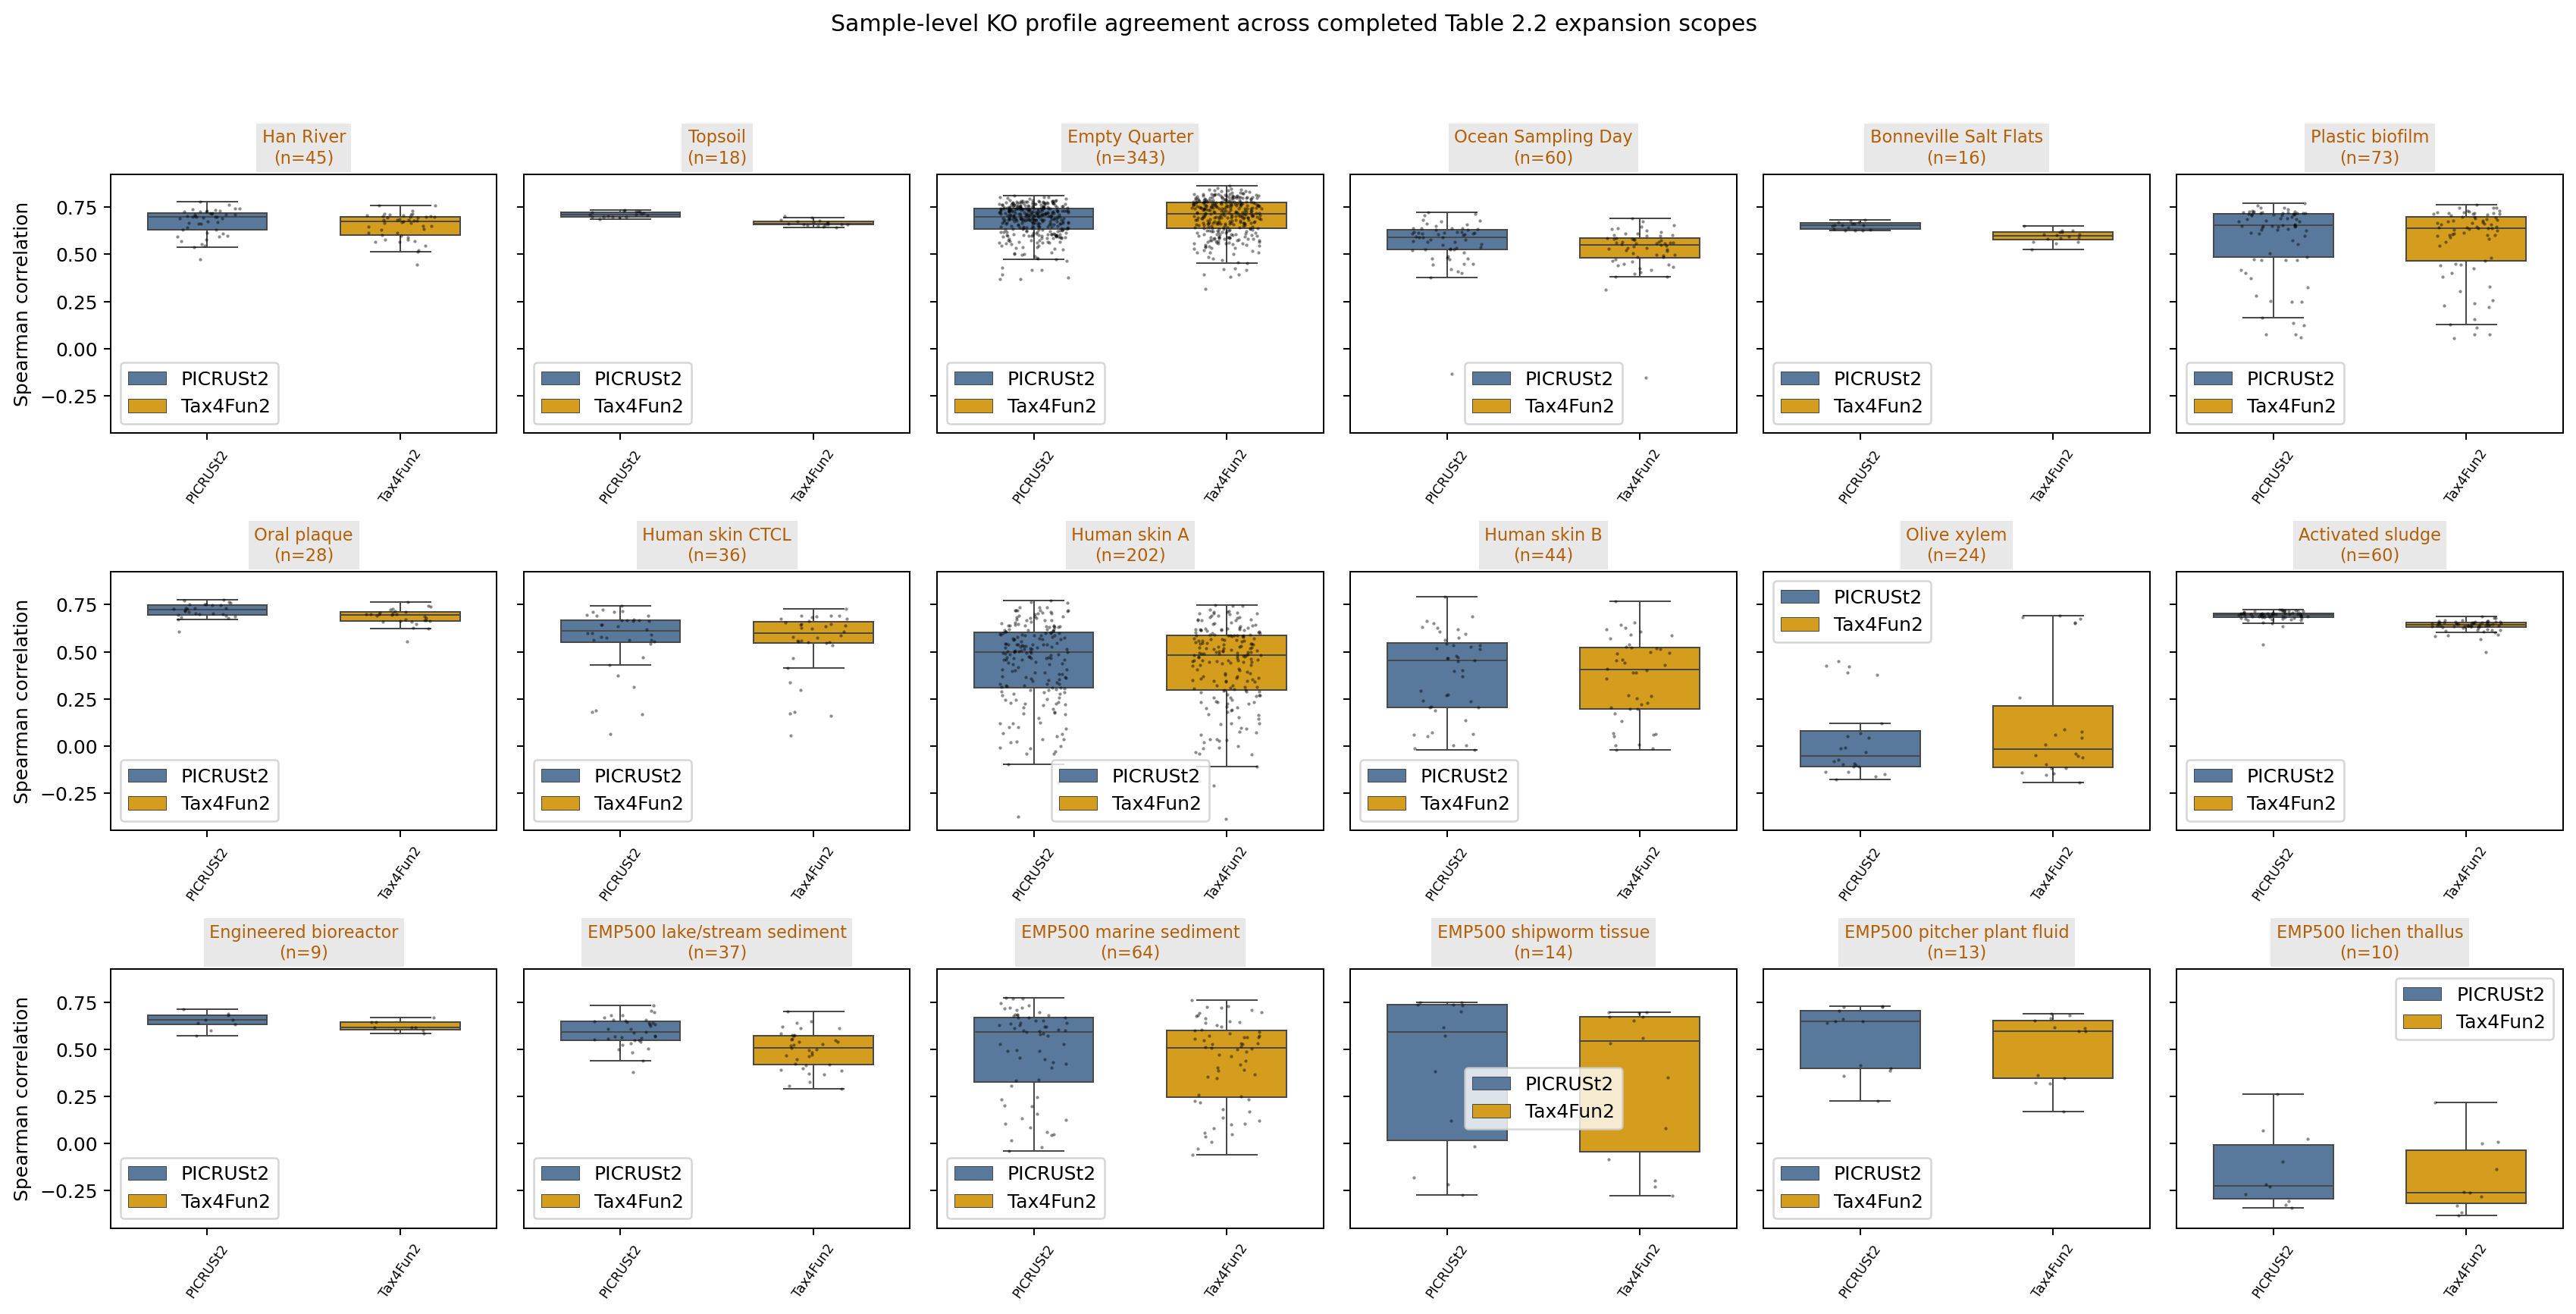

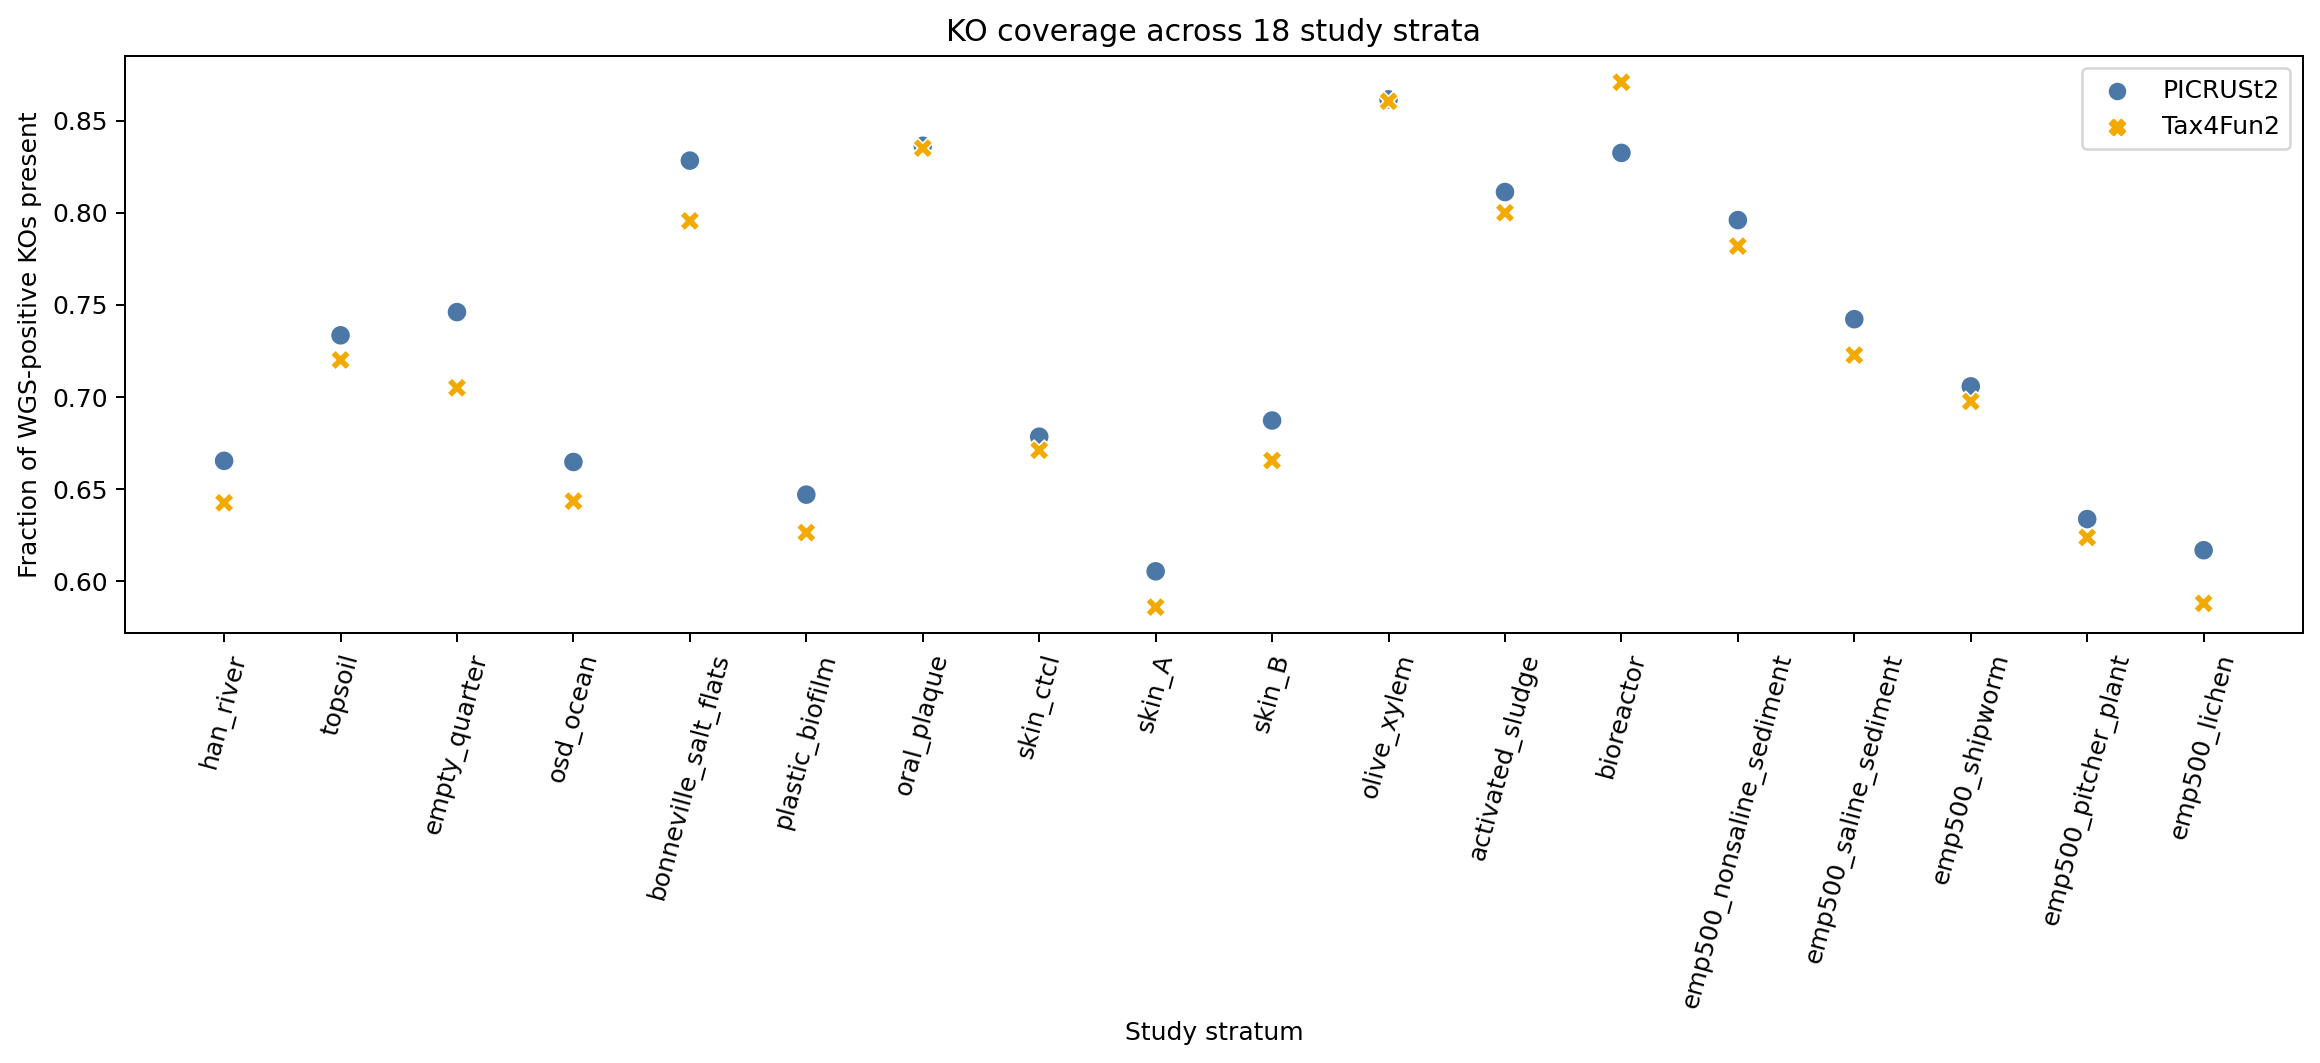

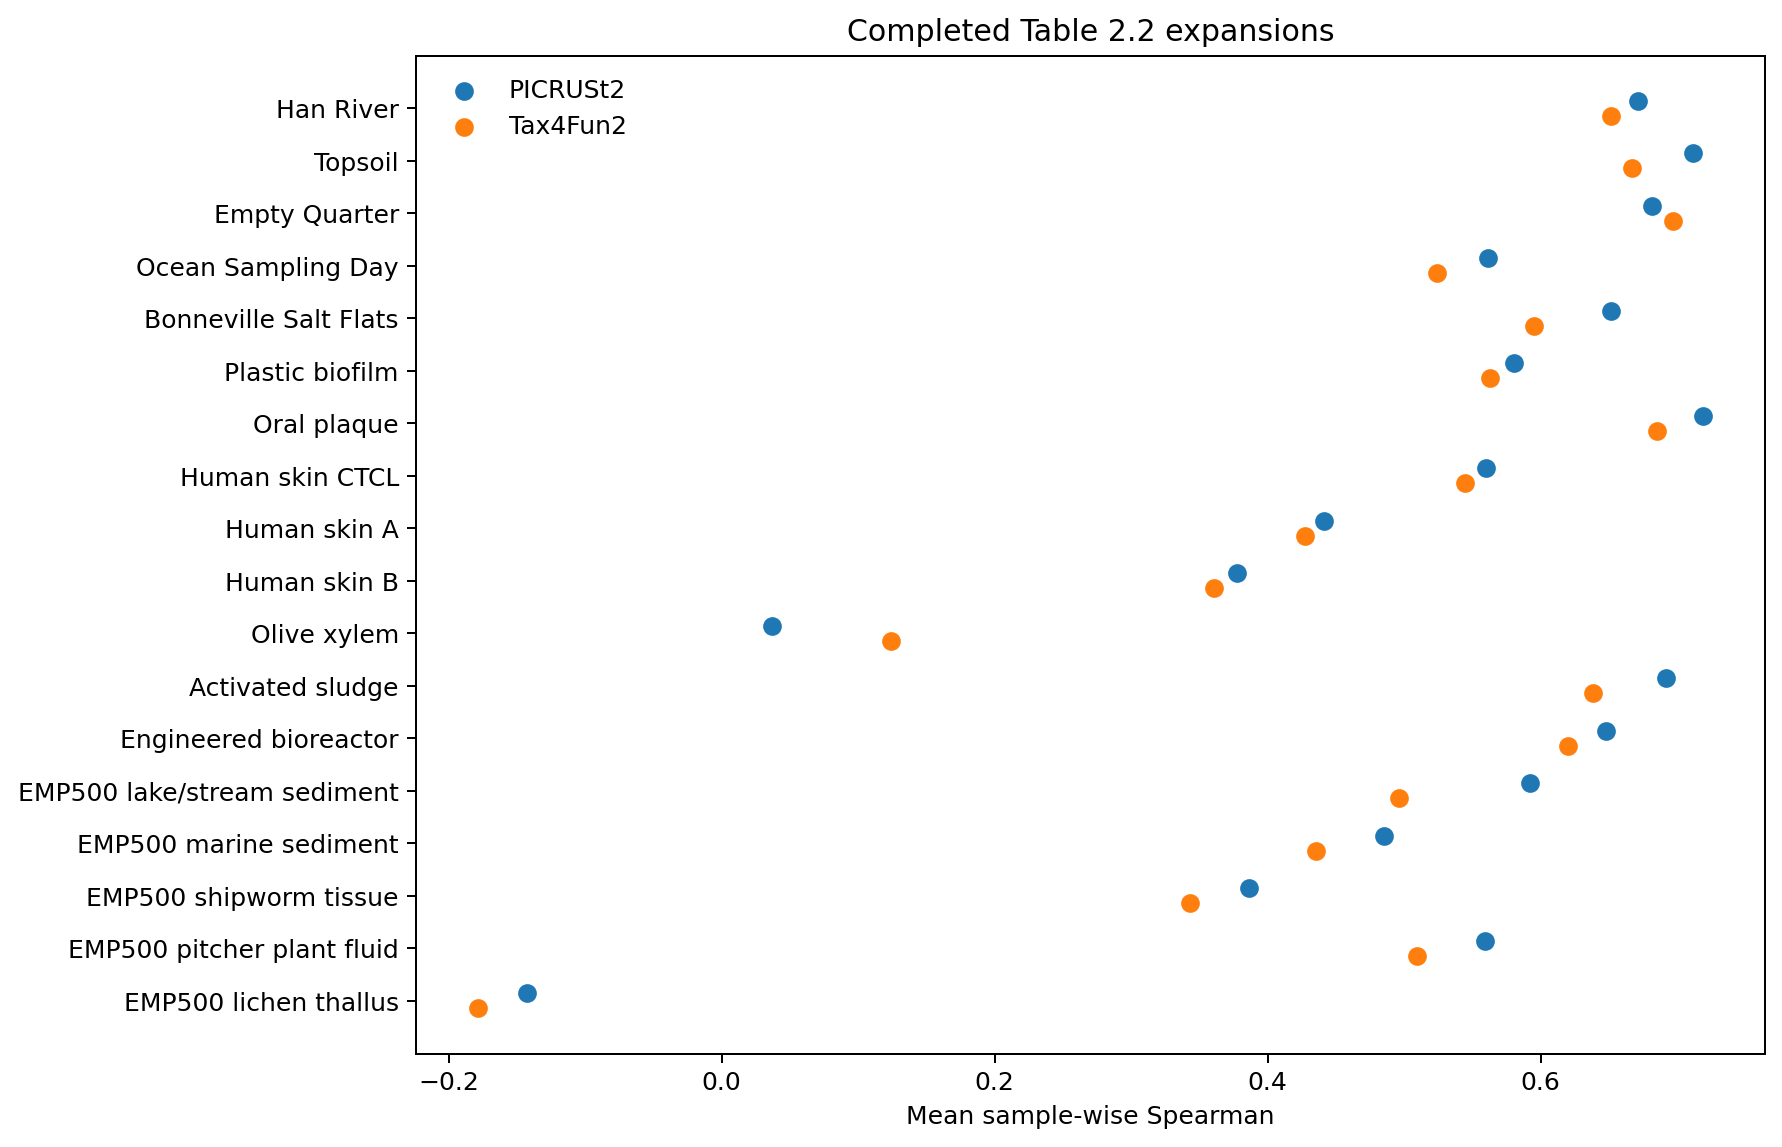

In [3]:
profile = pd.read_csv(ROOT / "results/profile_summary.tsv", sep="\t")
display(profile.pivot(index=["display_name", "n_samples"], columns="method_label",
                      values=["mean_sample_spearman", "mean_wgs_richness_recovered"]))
display(Image(filename=str(ROOT / "figures/01_profile_spearman_all_completed_expansions.png")))
display(Image(filename=str(ROOT / "figures/02_ko_coverage_all_completed_expansions.png")))
display(Image(filename=str(ROOT / "figures/10_profile_mean_summary.png")))

## Biological contrasts and availability

Group metrics are restricted to completed label designs. Accepted controls,
explicit metadata contrasts, provisional designs, and zero-BH contrasts are
kept visibly distinct. No group is invented for profile-only studies.

In [4]:
contrasts = pd.read_csv(ROOT / "results/contrast_manifest.tsv", sep="\t")
paper_availability = pd.read_csv(ROOT / "results/paper_metric_availability.tsv", sep="\t")
project_availability = pd.read_csv(ROOT / "results/project_metric_availability.tsv", sep="\t")
display(contrasts)
display(paper_availability)
display(project_availability)

,contrast_id,dataset,design,group_a,group_b,status,label_source,n_group_a,n_group_b,n_pairs
0,control_han_river_upstream_vs_downstream,han_river,unpaired,upstream,downstream,accepted_control,frozen expansion validation label registry r2,30,15,NaN
1,control_activated_sludge_disturbed_vs_stable,activated_sludge,unpaired,disturbed,stable,accepted_control,frozen expansion validation label registry r2,16,17,NaN
2,control_topsoil_control_vs_warmed,topsoil,unpaired,control,warmed,accepted_control_zero_bh,frozen expansion validation label registry r2,5,6,NaN
3,topsoil_biome_tundra_vs_temperate_grassland,topsoil,unpaired,tundra,temperate grassland,computed_explicit_metadata,Stage-5 crosswalk environment_biome,11,7,NaN
4,olive_xylem_season1_FS17_vs_Kalamata,olive_xylem,unpaired,FS17,Kalamata,computed_provisional_zero_bh,documented sample-alias prefix; seasons separate,6,6,NaN
5,olive_xylem_season2_FS17_vs_Kalamata,olive_xylem,unpaired,FS17,Kalamata,computed_provisional_zero_bh,documented sample-alias prefix; seasons separate,6,6,NaN
6,han_river_summer_vs_winter_site_paired,han_river,paired,summer_Aug2016,winter_Feb2017,computed_provisional,Stage-5 tranche; month/season interpretation r...,15,15,15.0
7,empty_quarter_surface_vs_deep_site_paired,empty_quarter,paired,surface_soil,deep_soil,computed_provisional,sample suffix plus trip/site blocks; primary l...,45,45,45.0
8,empty_quarter_rhizosphere_vs_surface_site_paired,empty_quarter,paired,rhizosphere,surface_soil,computed_provisional,sample suffix plus trip/site blocks; primary l...,47,47,47.0


,contrast_id,prediction_method,paper_metric_status,n_zero_total_samples,zero_total_sample_ids,ko_surface_policy
0,control_han_river_upstream_vs_downstream,PICRUSt2,computed,0,NaN,WGS-and-one-method shared native KO surface
1,control_han_river_upstream_vs_downstream,Tax4Fun2,computed,0,NaN,WGS-and-one-method shared native KO surface
2,control_activated_sludge_disturbed_vs_stable,PICRUSt2,computed,0,NaN,WGS-and-one-method shared native KO surface
3,control_activated_sludge_disturbed_vs_stable,Tax4Fun2,computed,0,NaN,WGS-and-one-method shared native KO surface
4,control_topsoil_control_vs_warmed,PICRUSt2,computed,0,NaN,WGS-and-one-method shared native KO surface
5,control_topsoil_control_vs_warmed,Tax4Fun2,computed,0,NaN,WGS-and-one-method shared native KO surface
6,topsoil_biome_tundra_vs_temperate_grassland,PICRUSt2,computed,0,NaN,WGS-and-one-method shared native KO surface
7,topsoil_biome_tundra_vs_temperate_grassland,Tax4Fun2,computed,0,NaN,WGS-and-one-method shared native KO surface
8,olive_xylem_season1_FS17_vs_Kalamata,PICRUSt2,computed,0,NaN,WGS-and-one-method shared native KO surface
9,olive_xylem_season1_FS17_vs_Kalamata,Tax4Fun2,unavailable_zero_total_on_pairwise_shared_ko_s...,2,Kal1-53;Kal1-65,WGS-and-one-method shared native KO surface


,contrast_id,prediction_method,project_metric_status,n_zero_total_samples,zero_total_sample_ids
0,control_han_river_upstream_vs_downstream,PICRUSt2,computed,0,NaN
1,control_han_river_upstream_vs_downstream,Tax4Fun2,computed,0,NaN
2,control_activated_sludge_disturbed_vs_stable,PICRUSt2,computed,0,NaN
3,control_activated_sludge_disturbed_vs_stable,Tax4Fun2,computed,0,NaN
4,control_topsoil_control_vs_warmed,PICRUSt2,computed,0,NaN
5,control_topsoil_control_vs_warmed,Tax4Fun2,computed,0,NaN
6,topsoil_biome_tundra_vs_temperate_grassland,PICRUSt2,computed,0,NaN
7,topsoil_biome_tundra_vs_temperate_grassland,Tax4Fun2,computed,0,NaN
8,olive_xylem_season1_FS17_vs_Kalamata,PICRUSt2,computed,0,NaN
9,olive_xylem_season1_FS17_vs_Kalamata,Tax4Fun2,unavailable_zero_total_native_prediction,2,Kal1-53;Kal1-65


## Matchado-derived recovery and randomization

This section uses two-sided rank-sum tests and **unadjusted** *p* < 0.05 for
significant-KO set recovery, plus 20 prediction-label randomizations. These
definitions are derived from Matchado et al. (2024). Pairwise WGS/model KO
intersections are this repository's stated surface choice. AUROC/AUPR rows
returned by the function are project additions, not Matchado metrics.

,dataset,prediction_method,metric,estimate,permutation_mean,permutation_sd,permutation_min,permutation_max,observed_minus_permutation_mean,n_permutations,...,n_prediction_significant,tp,fp,fn,randomization_method,published_source,published_source_doi,multiple_testing_method,significance_rule,metric_provenance
0,control_han_river_upstream_vs_downstream,PICRUSt2,precision,0.295511,0.204933,0.055053,0.111111,0.333333,0.090578,20,...,1604,474,1130,969,matchado_2024_prediction_phenotype_label_permu...,Matchado et al. 2024,10.1099/mgen.0.001203,none_unadjusted_pvalue,pvalue < 0.05,published_matchado
1,control_han_river_upstream_vs_downstream,PICRUSt2,recall,0.328482,0.042550,0.059844,0.001386,0.196812,0.285932,20,...,1604,474,1130,969,matchado_2024_prediction_phenotype_label_permu...,Matchado et al. 2024,10.1099/mgen.0.001203,none_unadjusted_pvalue,pvalue < 0.05,published_matchado
2,control_han_river_upstream_vs_downstream,PICRUSt2,f1,0.311126,0.058224,0.067220,0.002738,0.215560,0.252902,20,...,1604,474,1130,969,matchado_2024_prediction_phenotype_label_permu...,Matchado et al. 2024,10.1099/mgen.0.001203,none_unadjusted_pvalue,pvalue < 0.05,published_matchado
5,control_han_river_upstream_vs_downstream,Tax4Fun2,precision,0.301682,0.242914,0.062054,0.116279,0.324324,0.058767,20,...,1011,305,706,1113,matchado_2024_prediction_phenotype_label_permu...,Matchado et al. 2024,10.1099/mgen.0.001203,none_unadjusted_pvalue,pvalue < 0.05,published_matchado
6,control_han_river_upstream_vs_downstream,Tax4Fun2,recall,0.215092,0.045769,0.064377,0.002116,0.271509,0.169323,20,...,1011,305,706,1113,matchado_2024_prediction_phenotype_label_permu...,Matchado et al. 2024,10.1099/mgen.0.001203,none_unadjusted_pvalue,pvalue < 0.05,published_matchado
7,control_han_river_upstream_vs_downstream,Tax4Fun2,f1,0.251132,0.063382,0.066102,0.004170,0.251963,0.187750,20,...,1011,305,706,1113,matchado_2024_prediction_phenotype_label_permu...,Matchado et al. 2024,10.1099/mgen.0.001203,none_unadjusted_pvalue,pvalue < 0.05,published_matchado
10,control_activated_sludge_disturbed_vs_stable,PICRUSt2,precision,0.563215,0.527814,0.095459,0.288889,0.672619,0.035401,20,...,3670,2067,1603,943,matchado_2024_prediction_phenotype_label_permu...,Matchado et al. 2024,10.1099/mgen.0.001203,none_unadjusted_pvalue,pvalue < 0.05,published_matchado
11,control_activated_sludge_disturbed_vs_stable,PICRUSt2,recall,0.686711,0.034086,0.023234,0.004319,0.097342,0.652625,20,...,3670,2067,1603,943,matchado_2024_prediction_phenotype_label_permu...,Matchado et al. 2024,10.1099/mgen.0.001203,none_unadjusted_pvalue,pvalue < 0.05,published_matchado
12,control_activated_sludge_disturbed_vs_stable,PICRUSt2,f1,0.618862,0.062657,0.040227,0.008511,0.168246,0.556205,20,...,3670,2067,1603,943,matchado_2024_prediction_phenotype_label_permu...,Matchado et al. 2024,10.1099/mgen.0.001203,none_unadjusted_pvalue,pvalue < 0.05,published_matchado
15,control_activated_sludge_disturbed_vs_stable,Tax4Fun2,precision,0.556692,0.511232,0.101873,0.142857,0.640351,0.045460,20,...,3325,1851,1474,1146,matchado_2024_prediction_phenotype_label_permu...,Matchado et al. 2024,10.1099/mgen.0.001203,none_unadjusted_pvalue,pvalue < 0.05,published_matchado


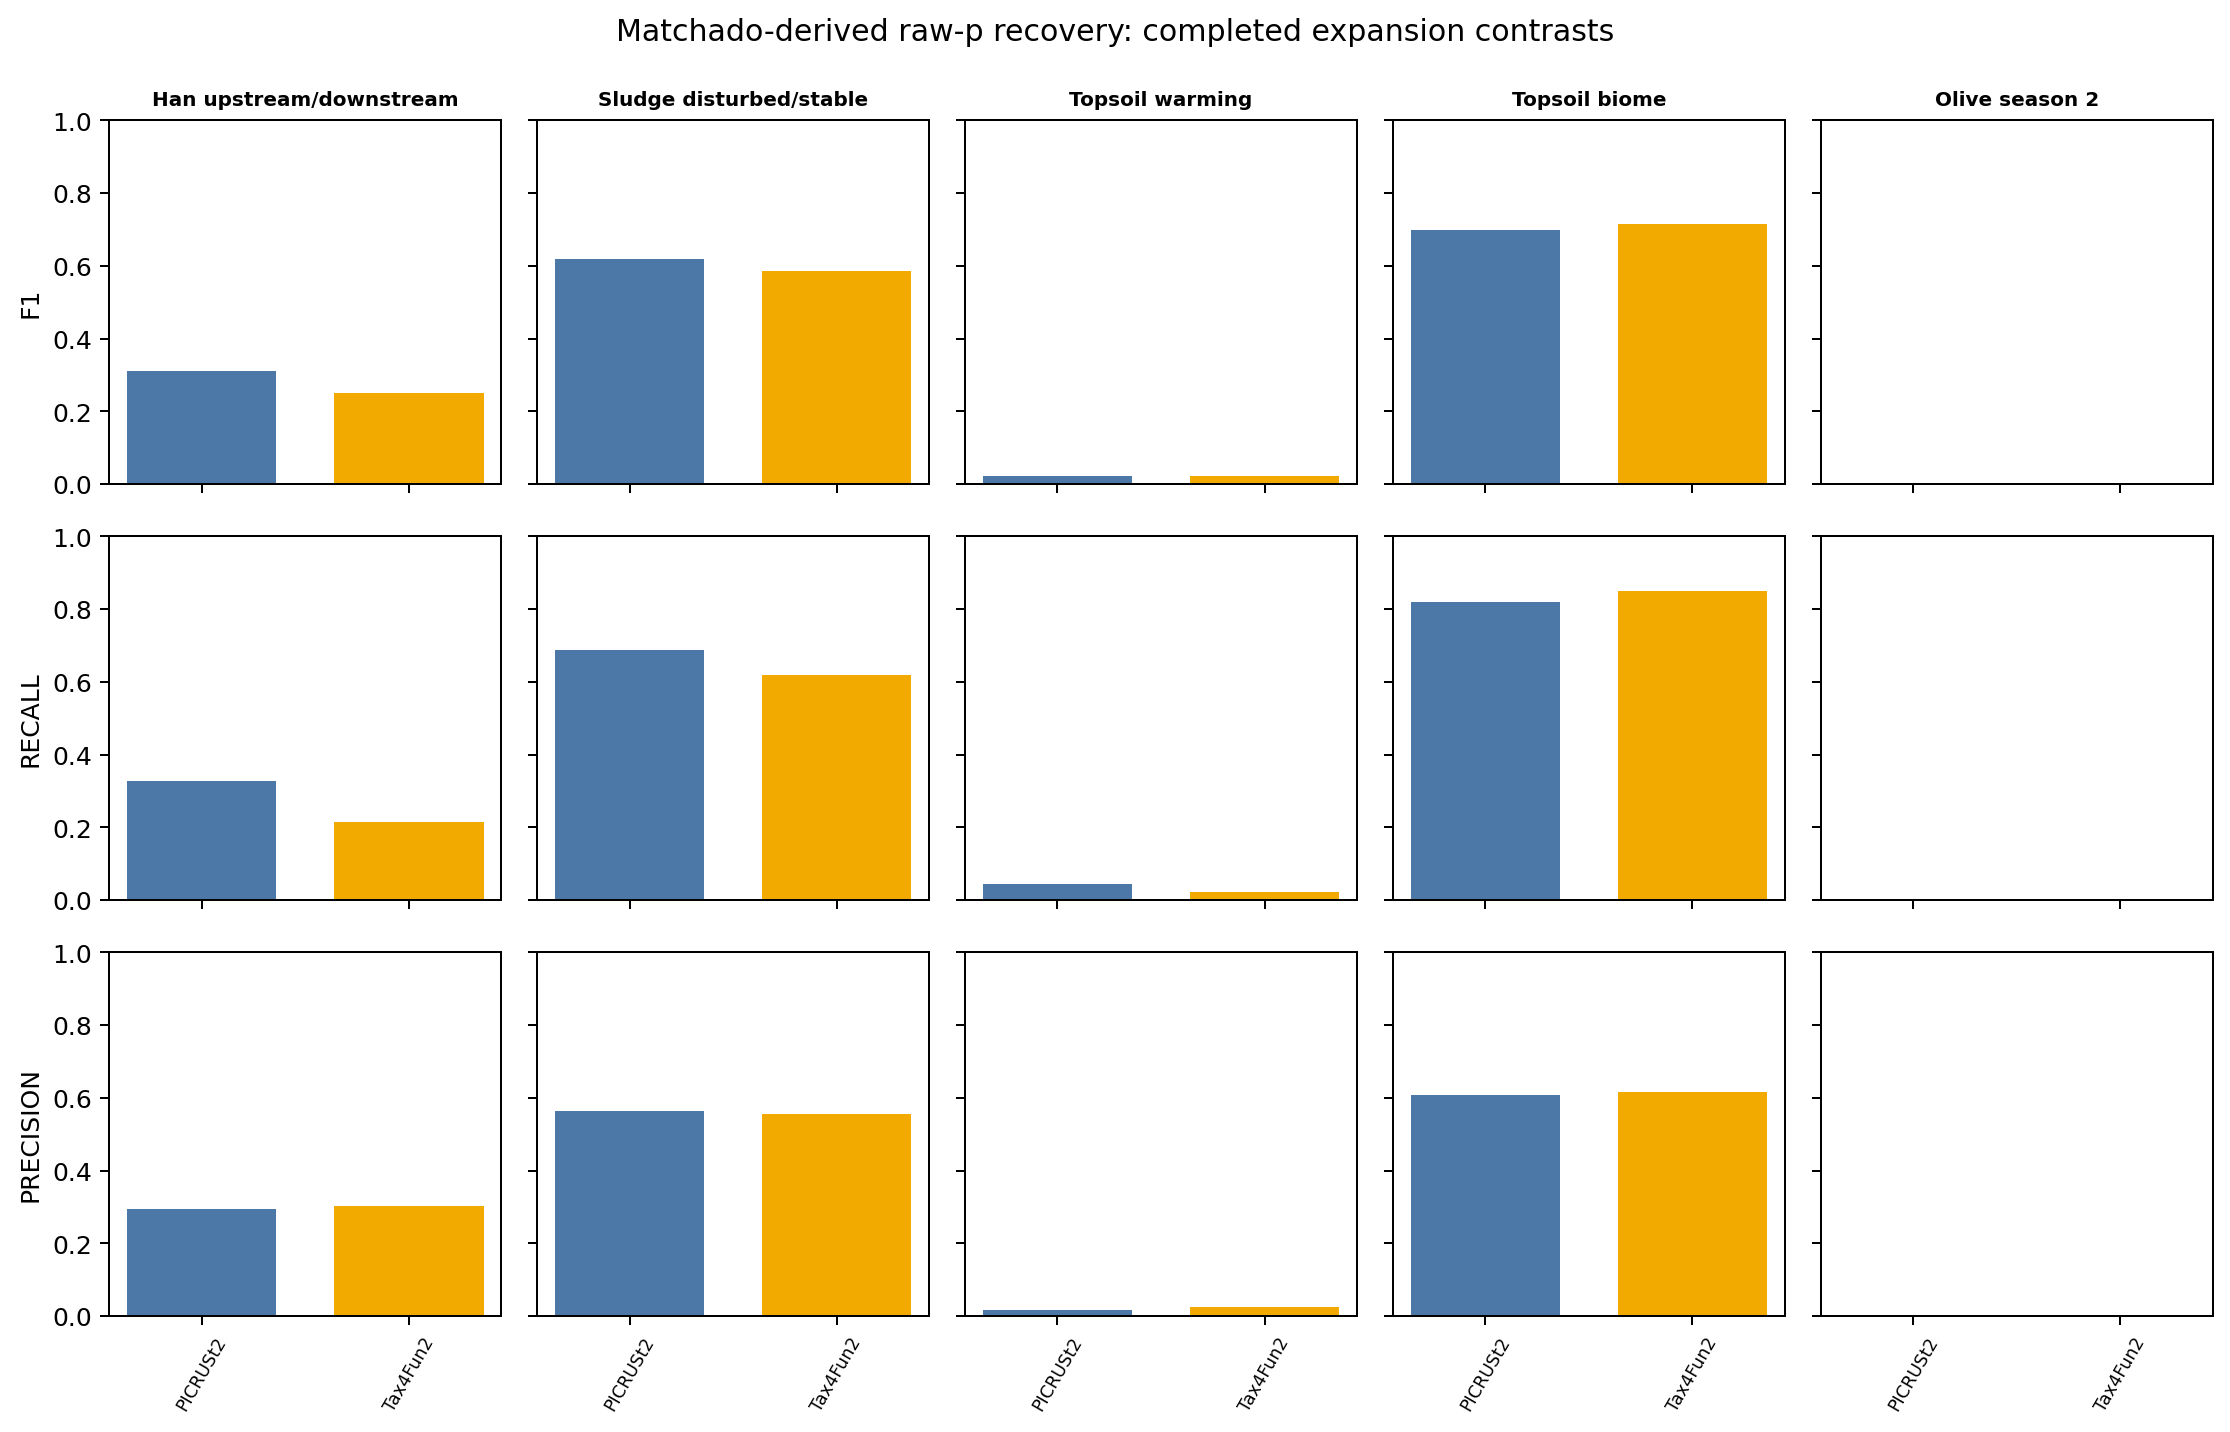

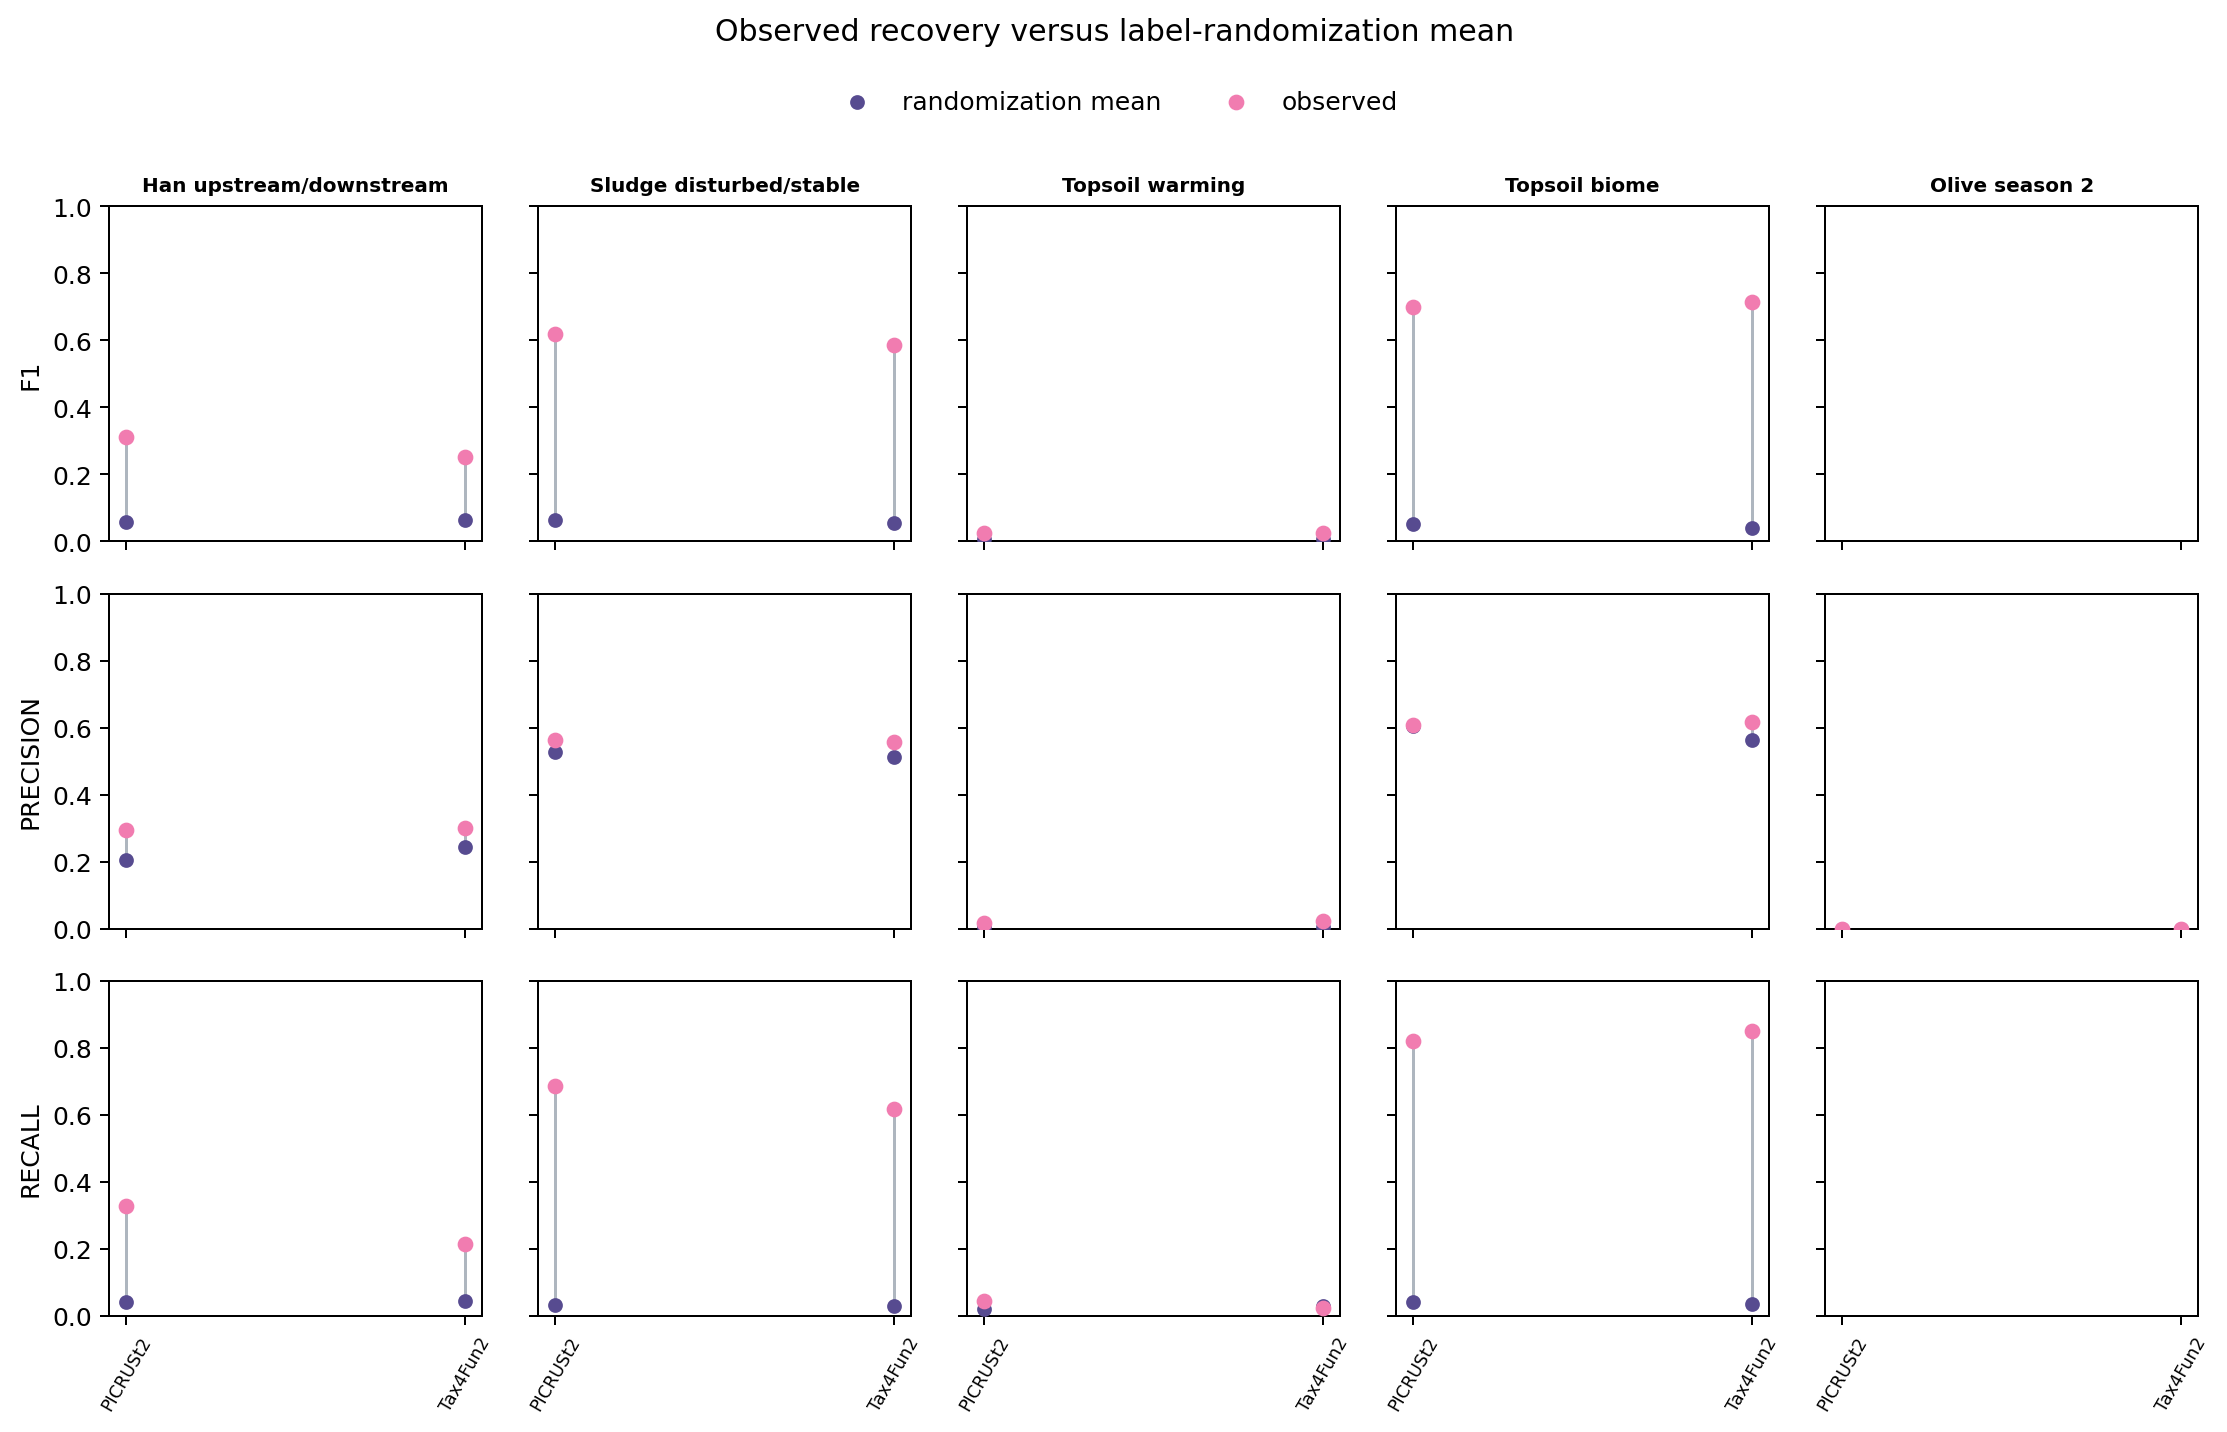

In [5]:
matchado = pd.read_csv(ROOT / "results/matchado_raw_p_summary.tsv", sep="\t")
display(matchado[matchado.metric.isin(["precision", "recall", "f1"])])
display(Image(filename=str(ROOT / "figures/03_matchado_raw_p_recovery.png")))
display(Image(filename=str(ROOT / "figures/04_matchado_label_randomization.png")))

## Sun-derived inference correlation and WGS-abundance controls

Signed `log10(p)` WGS-versus-prediction correlation and 100 independent WGS
KO-abundance shuffles are derived from Sun et al. (2020). The shuffled
control changes WGS abundances while holding group labels and predictions
fixed.

,dataset,observed_inference_correlation,observed_spearman_pvalue,observed_spearman_status,n_shared_nonzero_kos,prediction_method,randomization_mean,randomization_sd,randomization_min,randomization_max,n_randomizations,randomization_seed,randomization_method,published_source,published_source_doi,randomized_profile,fixed_profile,labels_permuted
0,control_han_river_upstream_vs_downstream,0.382625,2.781458e-245,defined,7070,PICRUSt2,-0.010044,0.012175,-0.037446,0.018397,100,20260901,sun_2020_independent_wgs_ko_abundance_permutation,Sun et al. 2020,10.1186/s40168-020-00815-y,WGS,prediction,False
1,control_han_river_upstream_vs_downstream,0.305078,4.955431e-147,defined,6828,Tax4Fun2,-0.018085,0.014164,-0.054716,0.016636,100,20260901,sun_2020_independent_wgs_ko_abundance_permutation,Sun et al. 2020,10.1186/s40168-020-00815-y,WGS,prediction,False
2,control_activated_sludge_disturbed_vs_stable,0.385014,1.273742e-205,defined,5838,PICRUSt2,-0.001118,0.013934,-0.031179,0.027160,100,20260901,sun_2020_independent_wgs_ko_abundance_permutation,Sun et al. 2020,10.1186/s40168-020-00815-y,WGS,prediction,False
3,control_activated_sludge_disturbed_vs_stable,0.276427,4.346174e-102,defined,5792,Tax4Fun2,-0.001740,0.013028,-0.037136,0.034227,100,20260901,sun_2020_independent_wgs_ko_abundance_permutation,Sun et al. 2020,10.1186/s40168-020-00815-y,WGS,prediction,False
4,control_topsoil_control_vs_warmed,0.157917,5.511338e-33,defined,5670,PICRUSt2,0.002044,0.013333,-0.031205,0.029793,100,20260901,sun_2020_independent_wgs_ko_abundance_permutation,Sun et al. 2020,10.1186/s40168-020-00815-y,WGS,prediction,False
5,control_topsoil_control_vs_warmed,0.085125,2.089417e-10,defined,5555,Tax4Fun2,0.001666,0.012523,-0.031528,0.029286,100,20260901,sun_2020_independent_wgs_ko_abundance_permutation,Sun et al. 2020,10.1186/s40168-020-00815-y,WGS,prediction,False
6,topsoil_biome_tundra_vs_temperate_grassland,0.231729,5.223889e-77,defined,6253,PICRUSt2,-0.002348,0.011716,-0.033632,0.023299,100,20260901,sun_2020_independent_wgs_ko_abundance_permutation,Sun et al. 2020,10.1186/s40168-020-00815-y,WGS,prediction,False
7,topsoil_biome_tundra_vs_temperate_grassland,0.155350,1.811142e-34,defined,6139,Tax4Fun2,-0.003737,0.013026,-0.030021,0.036296,100,20260901,sun_2020_independent_wgs_ko_abundance_permutation,Sun et al. 2020,10.1186/s40168-020-00815-y,WGS,prediction,False
8,olive_xylem_season1_FS17_vs_Kalamata,0.085658,1.760857e-03,defined,1331,PICRUSt2,0.002610,0.031303,-0.079697,0.075373,100,20260901,sun_2020_independent_wgs_ko_abundance_permutation,Sun et al. 2020,10.1186/s40168-020-00815-y,WGS,prediction,False
9,olive_xylem_season2_FS17_vs_Kalamata,0.389603,2.433138e-55,defined,1494,PICRUSt2,0.000345,0.021430,-0.043334,0.048145,100,20260901,sun_2020_independent_wgs_ko_abundance_permutation,Sun et al. 2020,10.1186/s40168-020-00815-y,WGS,prediction,False


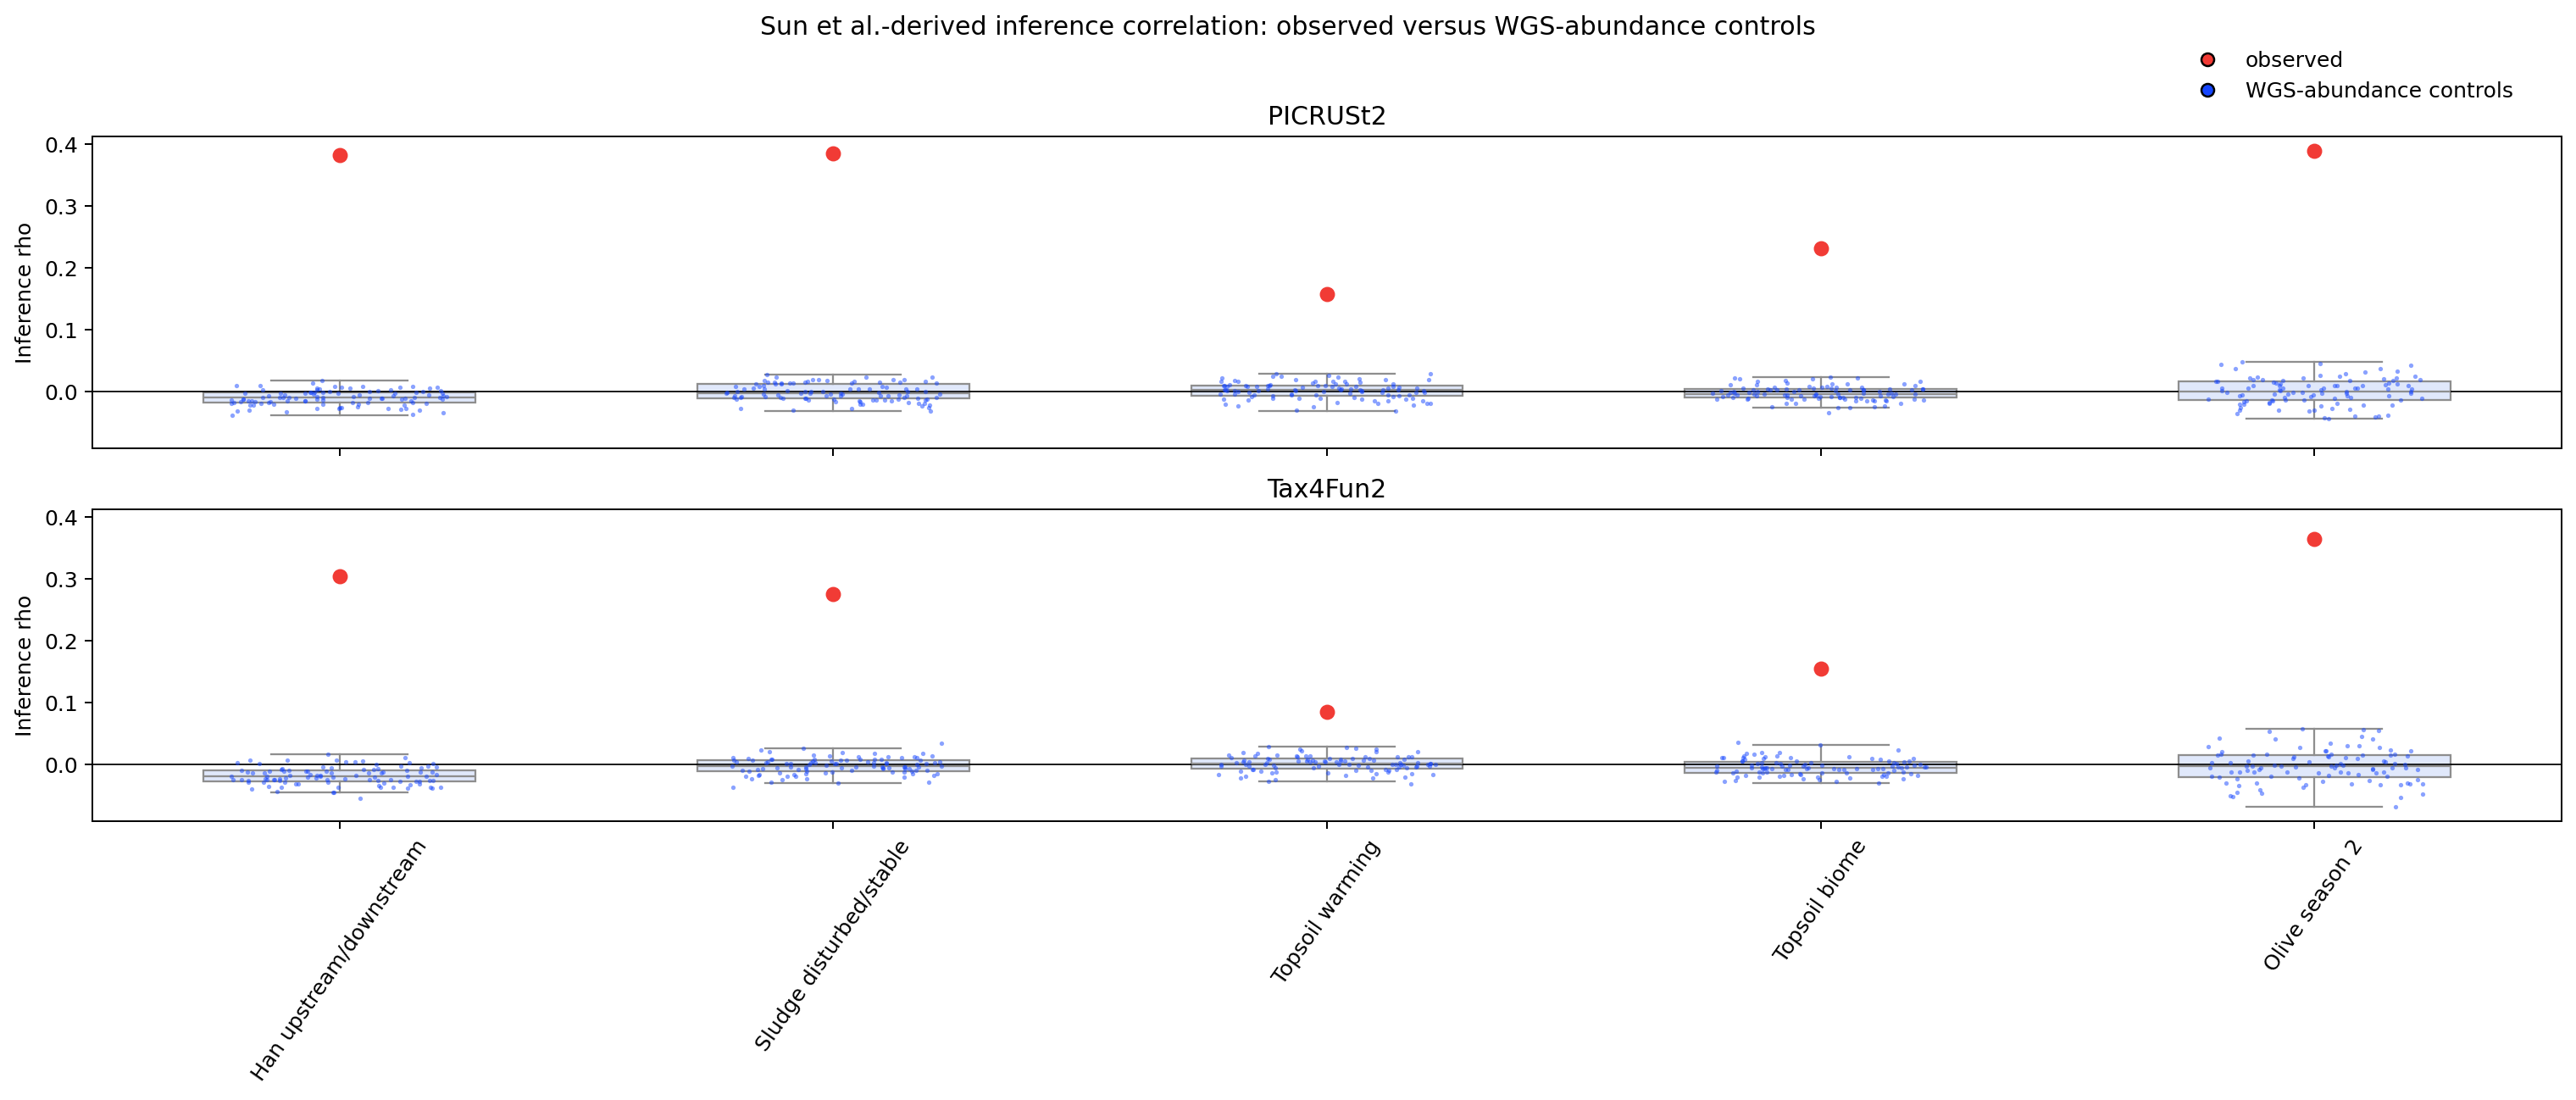

In [6]:
sun = pd.read_csv(ROOT / "results/sun_summary.tsv", sep="\t")
display(sun)
display(Image(filename=str(ROOT / "figures/05_sun_observed_and_wgs_abundance_controls.png")))

## Project extensions

These are not attributed to the benchmark papers. The WGS target family
requires detection in at least `max(5, ceil(10% × n))` labeled samples and
uses BH-adjusted *q* values within that family. Unpaired effects are
rank-biserial; paired effects use signed ranks after averaging replicates
within each matched side. Directional PR/ROC and deciles use WGS *q* ≤ 0.05
plus WGS effect sign as the observed target and continuous prediction effect
as the ranking score.

,dataset,prediction_method,tp,fp,fn,precision,recall,f1,n_tested_kos,n_wgs_significant,n_prediction_significant,prevalence_threshold,q_threshold,ko_family_policy,multiple_testing_method,significance_rule,metric_provenance,modification_reason
0,control_han_river_upstream_vs_downstream,PICRUSt2,76,630,466,0.107649,0.140221,0.121795,9145,542,706,0.05,0.05,wgs_only_prevalence_then_prediction_zero_fill,benjamini_hochberg_separately_within_wgs_and_e...,bh_qvalue < 0.05,project_bh_extension_not_matchado_raw_p,limit_false_discoveries_across_many_kos_and_fi...
1,control_han_river_upstream_vs_downstream,Tax4Fun2,33,224,509,0.128405,0.060886,0.082603,9145,542,257,0.05,0.05,wgs_only_prevalence_then_prediction_zero_fill,benjamini_hochberg_separately_within_wgs_and_e...,bh_qvalue < 0.05,project_bh_extension_not_matchado_raw_p,limit_false_discoveries_across_many_kos_and_fi...
2,control_activated_sludge_disturbed_vs_stable,PICRUSt2,1723,1713,1248,0.501455,0.579939,0.537849,6450,2971,3436,0.05,0.05,wgs_only_prevalence_then_prediction_zero_fill,benjamini_hochberg_separately_within_wgs_and_e...,bh_qvalue < 0.05,project_bh_extension_not_matchado_raw_p,limit_false_discoveries_across_many_kos_and_fi...
3,control_activated_sludge_disturbed_vs_stable,Tax4Fun2,1533,1521,1438,0.501965,0.515988,0.508880,6450,2971,3054,0.05,0.05,wgs_only_prevalence_then_prediction_zero_fill,benjamini_hochberg_separately_within_wgs_and_e...,bh_qvalue < 0.05,project_bh_extension_not_matchado_raw_p,limit_false_discoveries_across_many_kos_and_fi...
4,control_topsoil_control_vs_warmed,PICRUSt2,0,0,0,NaN,NaN,NaN,7562,0,0,0.05,0.05,wgs_only_prevalence_then_prediction_zero_fill,benjamini_hochberg_separately_within_wgs_and_e...,bh_qvalue < 0.05,project_bh_extension_not_matchado_raw_p,limit_false_discoveries_across_many_kos_and_fi...
5,control_topsoil_control_vs_warmed,Tax4Fun2,0,0,0,NaN,NaN,NaN,7562,0,0,0.05,0.05,wgs_only_prevalence_then_prediction_zero_fill,benjamini_hochberg_separately_within_wgs_and_e...,bh_qvalue < 0.05,project_bh_extension_not_matchado_raw_p,limit_false_discoveries_across_many_kos_and_fi...
6,topsoil_biome_tundra_vs_temperate_grassland,PICRUSt2,2798,2205,1288,0.559264,0.684777,0.615689,8525,4086,5003,0.05,0.05,wgs_only_prevalence_then_prediction_zero_fill,benjamini_hochberg_separately_within_wgs_and_e...,bh_qvalue < 0.05,project_bh_extension_not_matchado_raw_p,limit_false_discoveries_across_many_kos_and_fi...
7,topsoil_biome_tundra_vs_temperate_grassland,Tax4Fun2,2904,2218,1182,0.566966,0.710720,0.630756,8525,4086,5122,0.05,0.05,wgs_only_prevalence_then_prediction_zero_fill,benjamini_hochberg_separately_within_wgs_and_e...,bh_qvalue < 0.05,project_bh_extension_not_matchado_raw_p,limit_false_discoveries_across_many_kos_and_fi...
8,olive_xylem_season1_FS17_vs_Kalamata,PICRUSt2,0,0,0,NaN,NaN,NaN,1555,0,0,0.05,0.05,wgs_only_prevalence_then_prediction_zero_fill,benjamini_hochberg_separately_within_wgs_and_e...,bh_qvalue < 0.05,project_bh_extension_not_matchado_raw_p,limit_false_discoveries_across_many_kos_and_fi...
9,olive_xylem_season2_FS17_vs_Kalamata,PICRUSt2,0,0,0,NaN,NaN,NaN,1681,0,0,0.05,0.05,wgs_only_prevalence_then_prediction_zero_fill,benjamini_hochberg_separately_within_wgs_and_e...,bh_qvalue < 0.05,project_bh_extension_not_matchado_raw_p,limit_false_discoveries_across_many_kos_and_fi...


,contrast_id,dataset,design,prediction_method,n_kos,n_wgs_bh_selected,spearman_effect_all,pearson_effect_all,spearman_effect_wgs_bh_selected,pearson_effect_wgs_bh_selected
0,control_han_river_upstream_vs_downstream,han_river,unpaired,PICRUSt2,8393,509,0.384299,0.390341,0.467037,0.542219
1,control_han_river_upstream_vs_downstream,han_river,unpaired,Tax4Fun2,8393,509,0.281211,0.302433,0.391974,0.484716
2,control_activated_sludge_disturbed_vs_stable,activated_sludge,unpaired,PICRUSt2,5829,2989,0.371381,0.370965,0.464721,0.468015
3,control_activated_sludge_disturbed_vs_stable,activated_sludge,unpaired,Tax4Fun2,5829,2989,0.269186,0.272467,0.340652,0.354429
4,control_topsoil_control_vs_warmed,topsoil,unpaired,PICRUSt2,5593,0,0.132938,0.142121,NaN,NaN
5,control_topsoil_control_vs_warmed,topsoil,unpaired,Tax4Fun2,5593,0,0.065603,0.065812,NaN,NaN
6,topsoil_biome_tundra_vs_temperate_grassland,topsoil,unpaired,PICRUSt2,6230,4180,0.247390,0.221489,0.293256,0.273223
7,topsoil_biome_tundra_vs_temperate_grassland,topsoil,unpaired,Tax4Fun2,6230,4180,0.161752,0.143647,0.192387,0.182621
8,olive_xylem_season1_FS17_vs_Kalamata,olive_xylem,unpaired,PICRUSt2,90,0,-0.073532,-0.068572,NaN,NaN
9,olive_xylem_season2_FS17_vs_Kalamata,olive_xylem,unpaired,PICRUSt2,636,0,0.189082,0.159802,NaN,NaN


,dataset,prediction_method,direction,K,target_total,baseline_target_prevalence,ap,roc_auc,status,mean_directional_ap,mean_directional_roc_auc
0,control_han_river_upstream_vs_downstream,PICRUSt2,positive,8393,196,0.023353,0.113582,0.752196,defined,0.106419,0.719566
1,control_han_river_upstream_vs_downstream,PICRUSt2,negative,8393,313,0.037293,0.099256,0.686936,defined,0.106419,0.719566
2,control_han_river_upstream_vs_downstream,Tax4Fun2,positive,8393,196,0.023353,0.050710,0.665577,defined,0.072663,0.679164
3,control_han_river_upstream_vs_downstream,Tax4Fun2,negative,8393,313,0.037293,0.094615,0.692752,defined,0.072663,0.679164
4,control_activated_sludge_disturbed_vs_stable,PICRUSt2,positive,5829,1616,0.277235,0.483371,0.693622,defined,0.426379,0.682263
5,control_activated_sludge_disturbed_vs_stable,PICRUSt2,negative,5829,1373,0.235546,0.369386,0.670905,defined,0.426379,0.682263
6,control_activated_sludge_disturbed_vs_stable,Tax4Fun2,positive,5829,1616,0.277235,0.401546,0.633211,defined,0.370925,0.636924
7,control_activated_sludge_disturbed_vs_stable,Tax4Fun2,negative,5829,1373,0.235546,0.340304,0.640638,defined,0.370925,0.636924
8,control_topsoil_control_vs_warmed,PICRUSt2,positive,5593,0,0.000000,NaN,NaN,undefined_no_targets,NaN,NaN
9,control_topsoil_control_vs_warmed,PICRUSt2,negative,5593,0,0.000000,NaN,NaN,undefined_no_targets,NaN,NaN


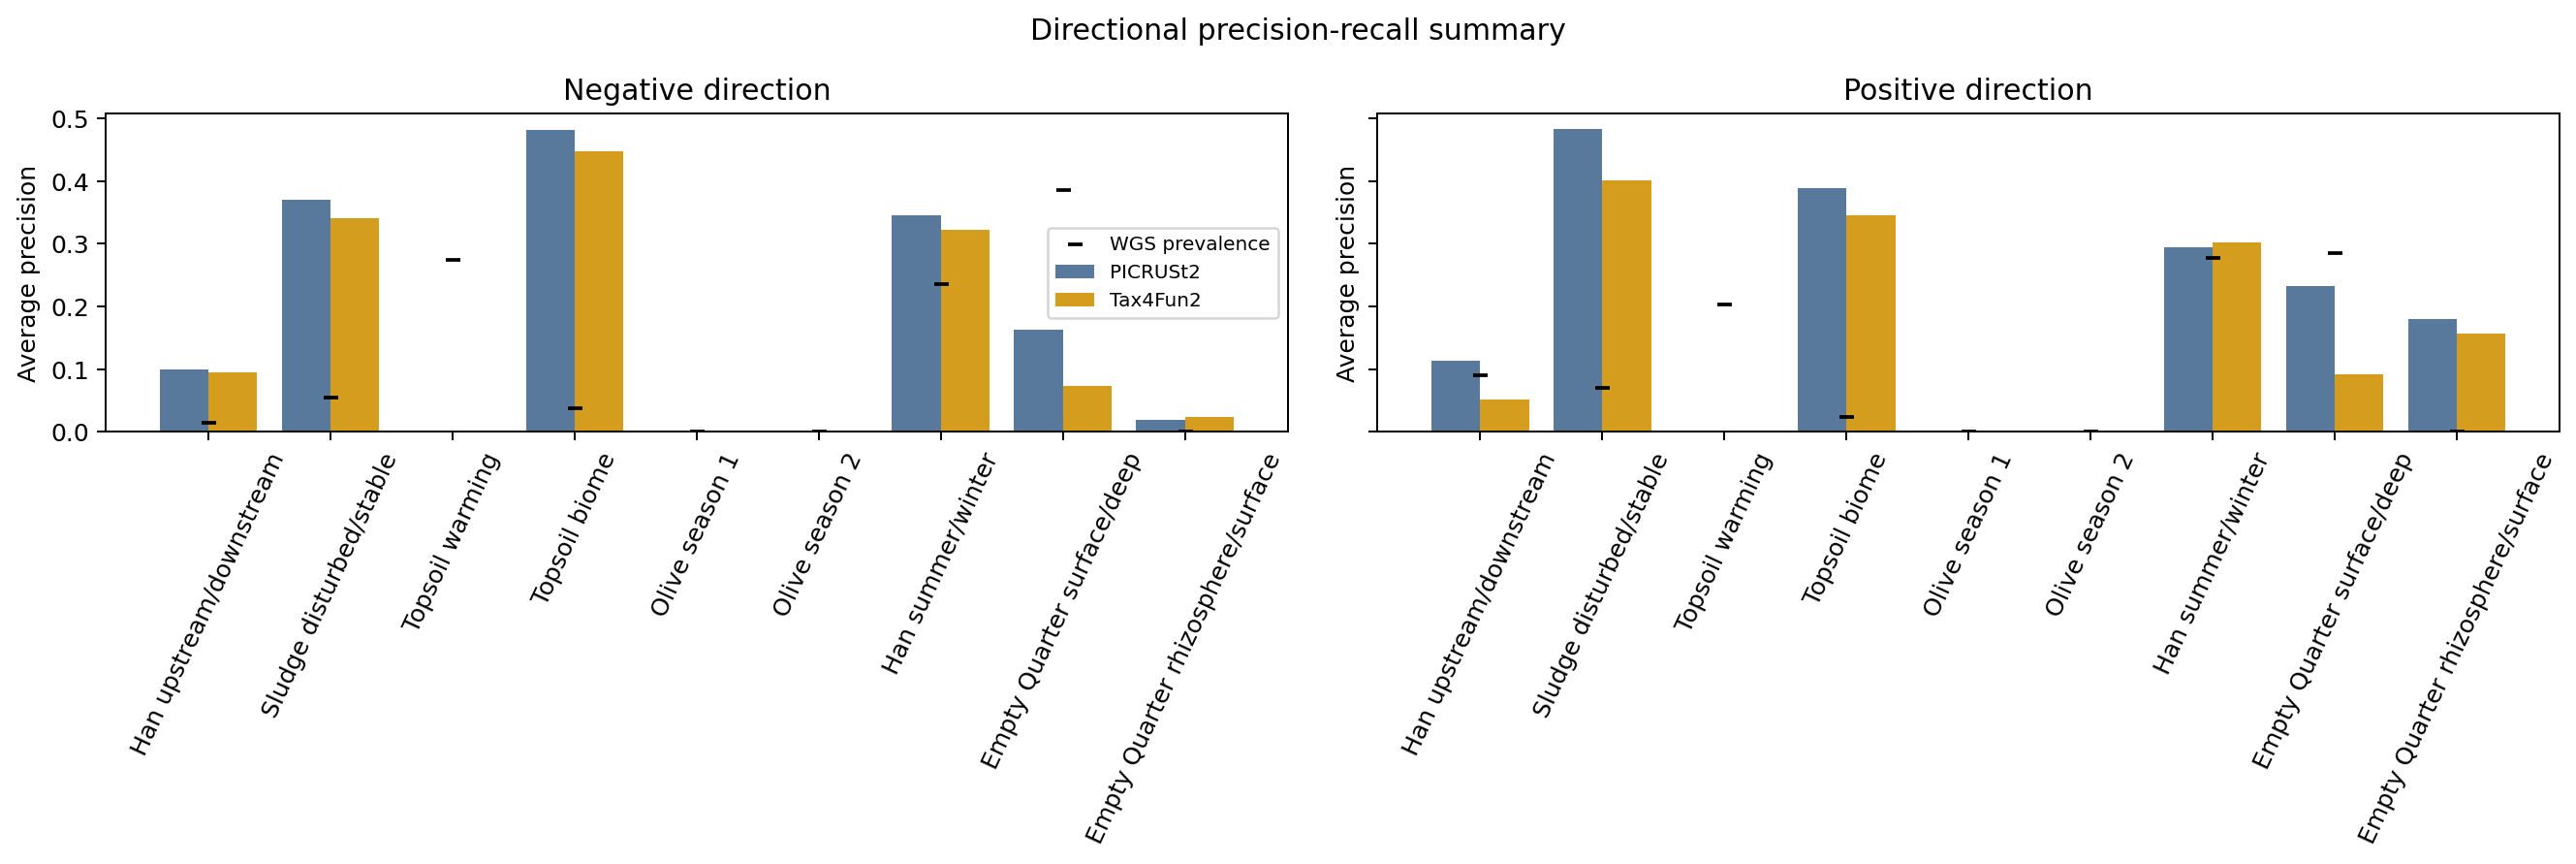

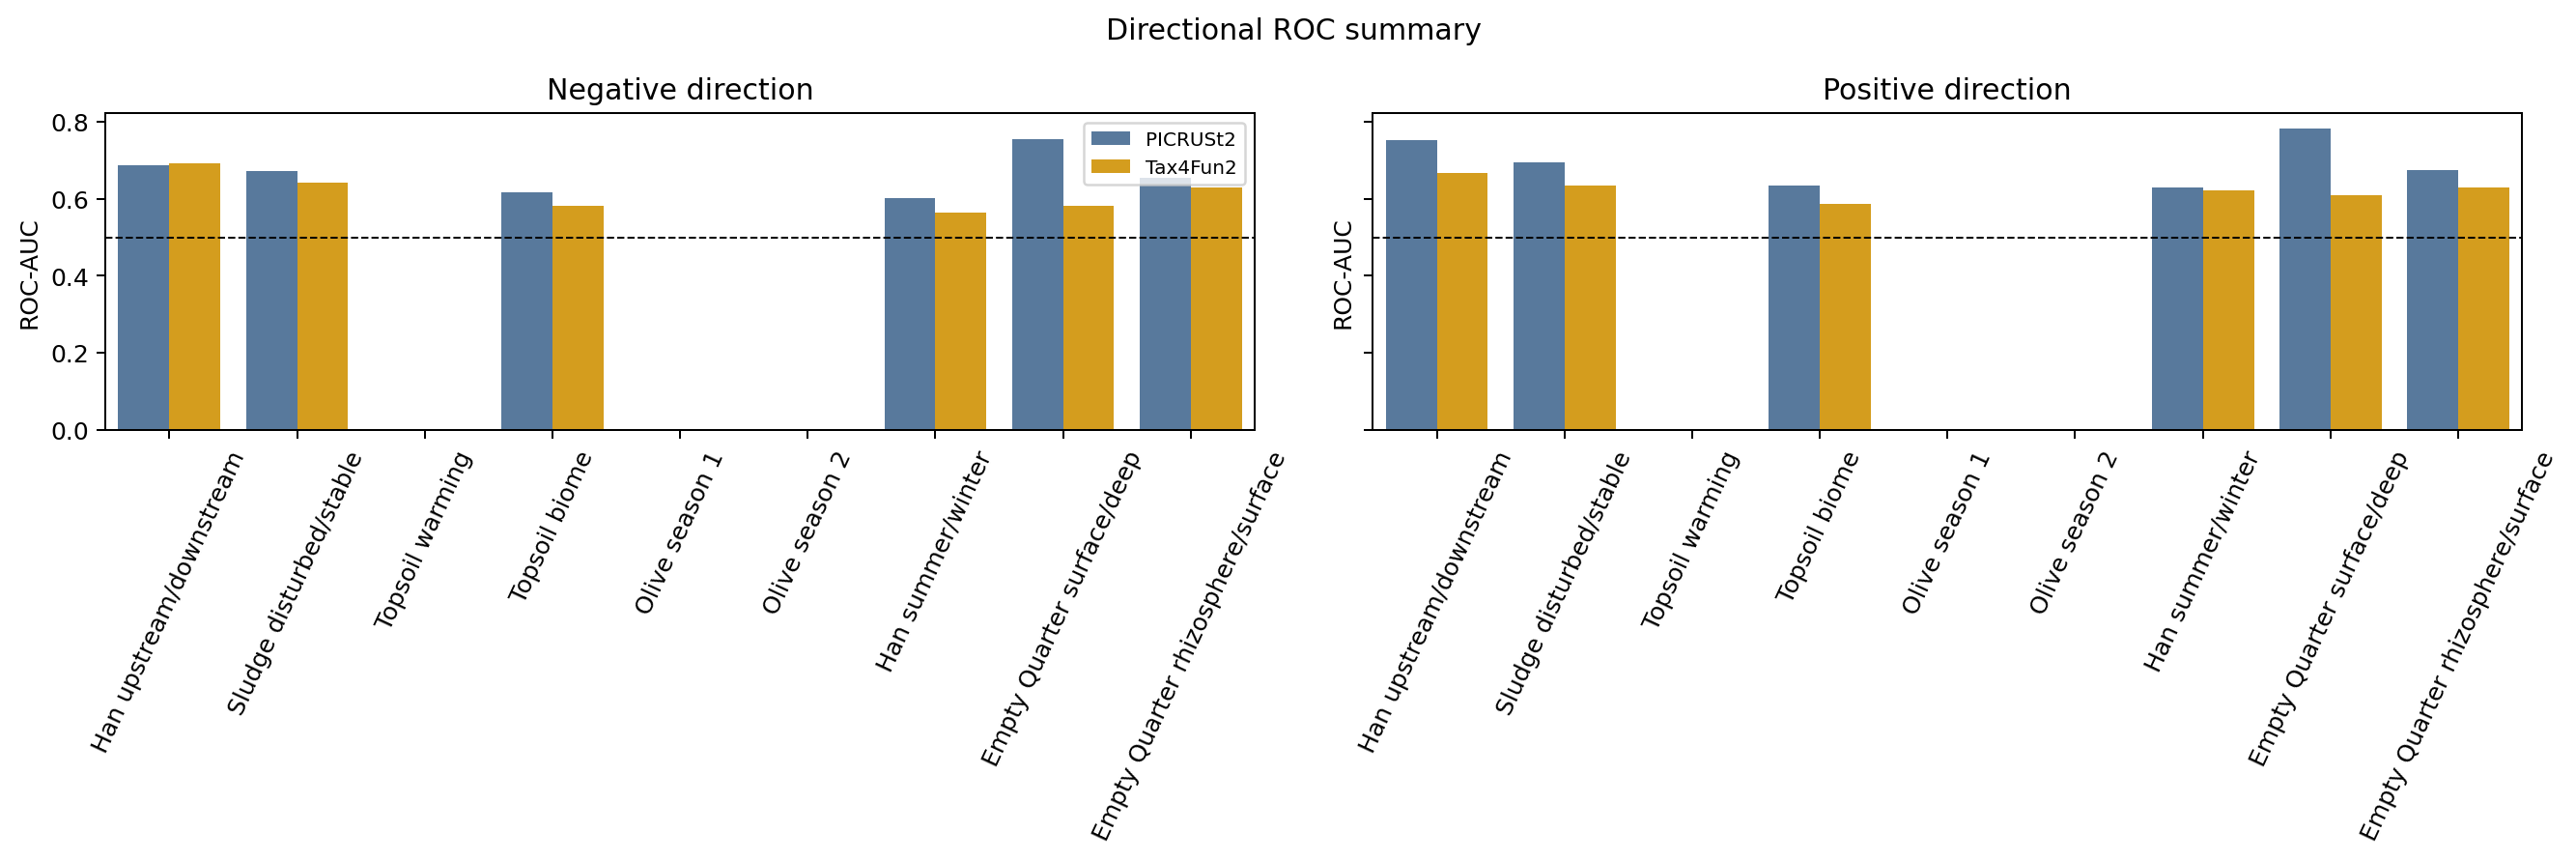

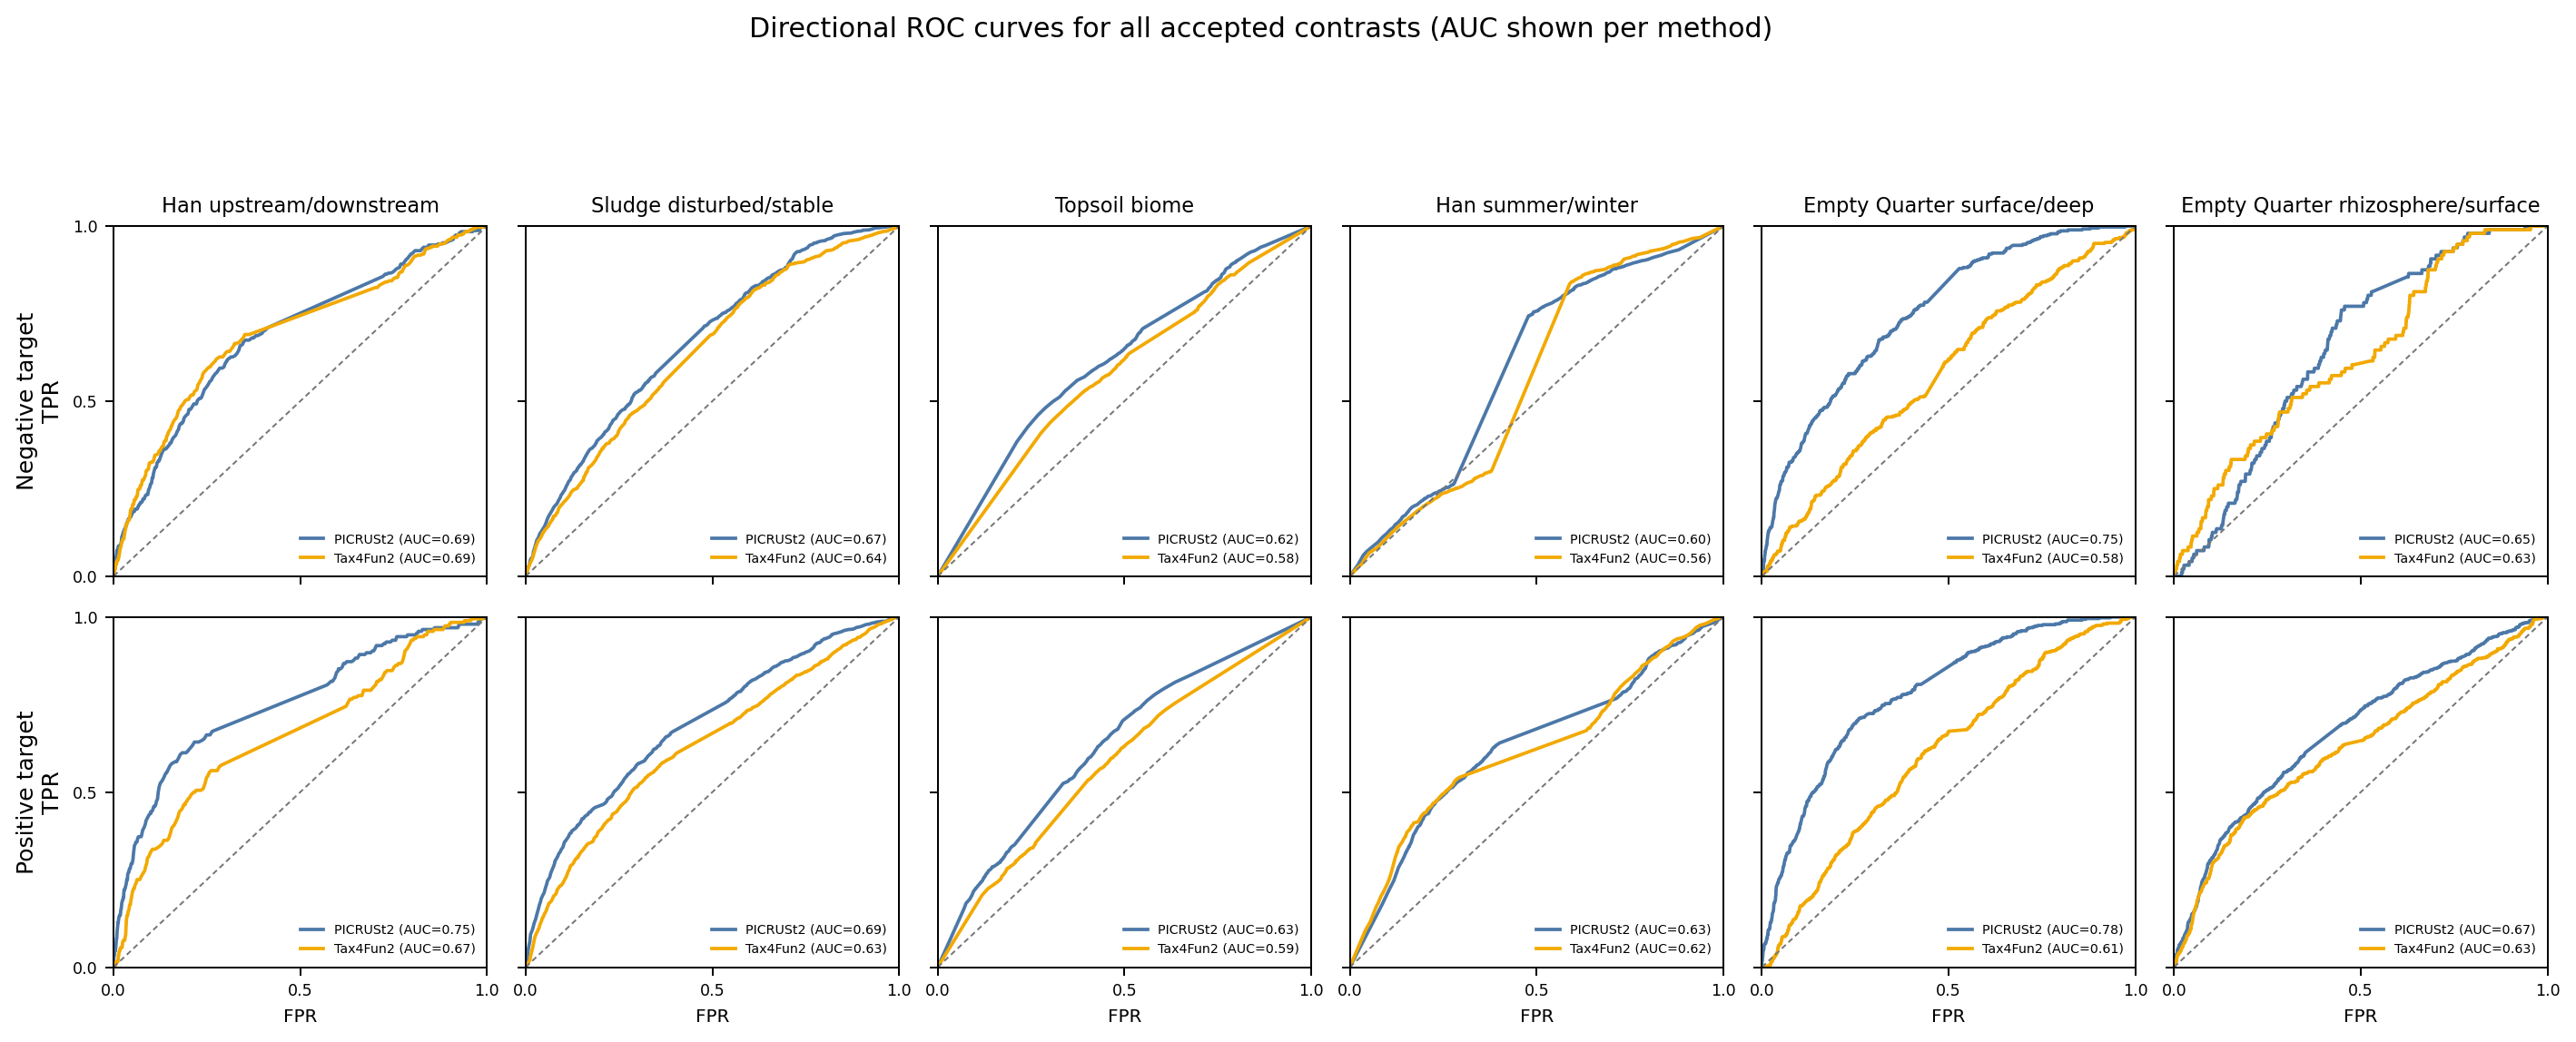

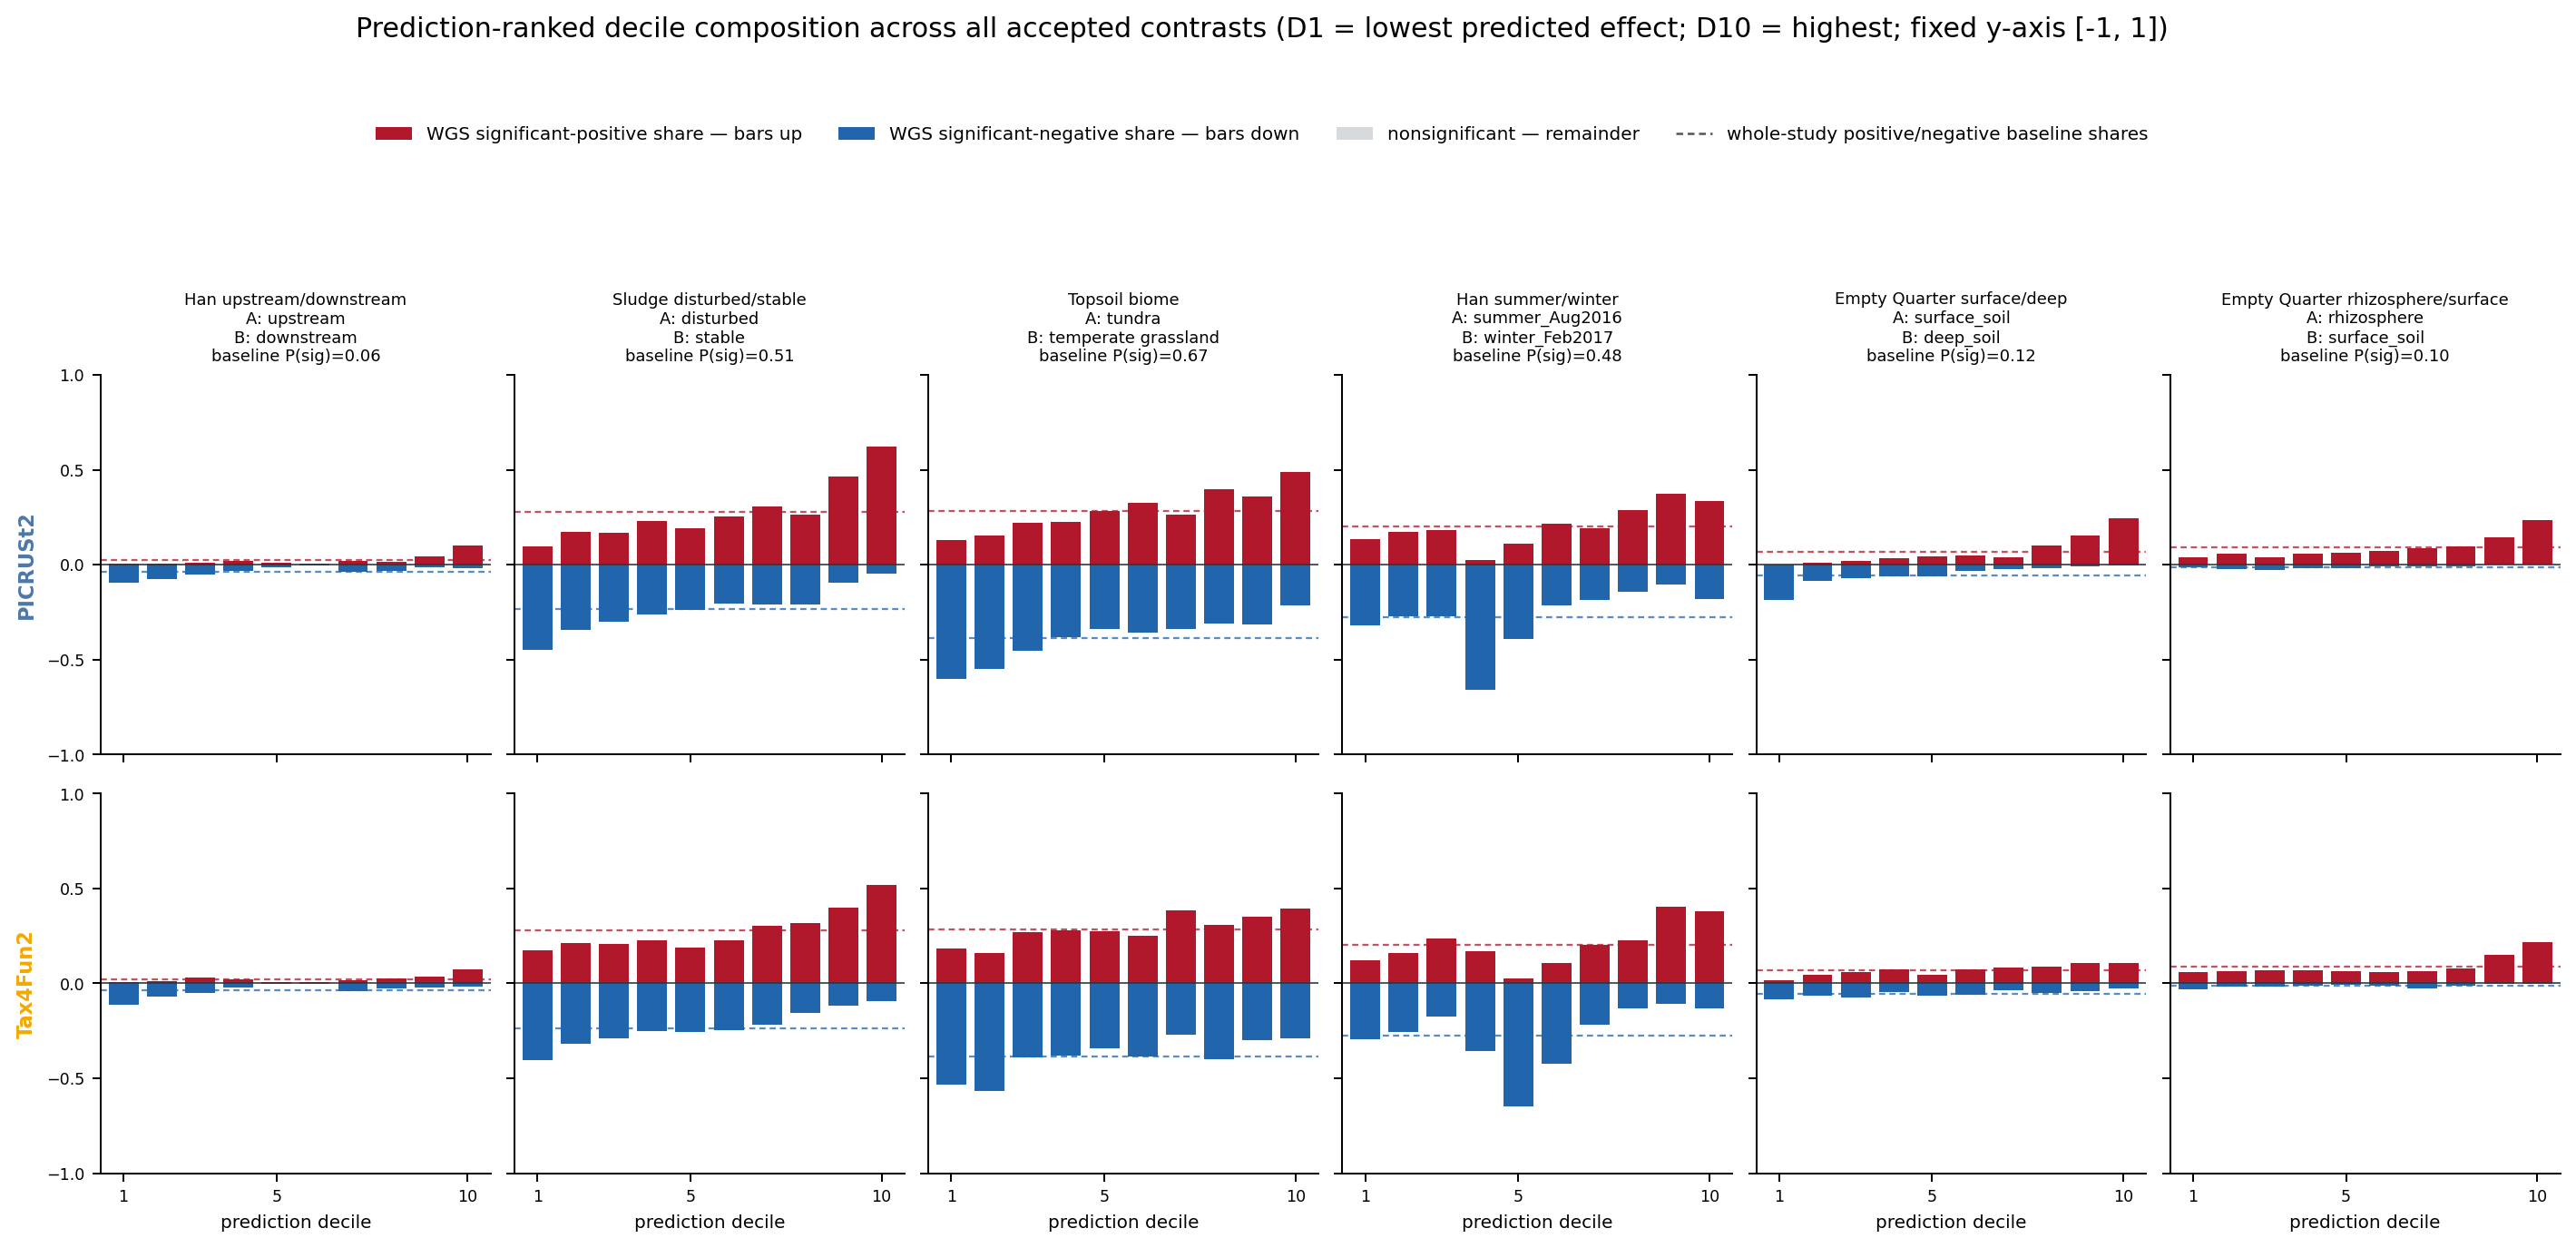

In [7]:
bh = pd.read_csv(ROOT / "results/project_bh_summary.tsv", sep="\t")
effects = pd.read_csv(ROOT / "results/effect_summary.tsv", sep="\t")
direction = pd.read_csv(ROOT / "results/directional_metric_summary.tsv", sep="\t")
display(bh)
display(effects)
display(direction)
display(Image(filename=str(ROOT / "figures/06_directional_average_precision.png")))
display(Image(filename=str(ROOT / "figures/07_directional_roc_auc.png")))
display(Image(filename=str(ROOT / "figures/08_directional_roc_curves.png")))
display(Image(filename=str(ROOT / "figures/09_directional_decile_composition.png")))

## Numerical validation against completed source results

The nine completed WGS contrast screens are independently replayed. Passing
requires exact ordered KO identity and maximum absolute differences no
larger than `1e-12` for p-values, BH q-values, and effect sizes. The Empty
Quarter profile surface has 343 strict paired samples; its historical screen
comparison deliberately uses the exact frozen 341-sample contrast contract.

In [8]:
validation = pd.read_csv(ROOT / "results/wgs_screen_validation.tsv", sep="\t")
assert validation.validation_pass.all()
assert validation.ko_identity_exact.all()
numeric = validation.filter(regex="^max_abs_diff_")
assert numeric.max().max() <= 1e-12
display(validation)
print("Largest absolute numerical difference:", numeric.max().max())

,contrast_id,reference_path,n_kos,ko_identity_exact,max_abs_diff_pvalue,max_abs_diff_bh_qvalue,max_abs_diff_effect,validation_pass
0,control_han_river_upstream_vs_downstream,/home/hernan_melmoth/Documents/phd_work/functi...,8393,True,1.110223e-16,1.110223e-16,1.110223e-16,True
1,control_activated_sludge_disturbed_vs_stable,/home/hernan_melmoth/Documents/phd_work/functi...,5829,True,1.110223e-16,1.110223e-16,1.110223e-16,True
2,control_topsoil_control_vs_warmed,/home/hernan_melmoth/Documents/phd_work/functi...,5593,True,1.110223e-16,0.000000e+00,1.110223e-16,True
3,topsoil_biome_tundra_vs_temperate_grassland,/home/hernan_melmoth/Documents/phd_work/functi...,6230,True,1.110223e-16,1.110223e-16,9.194034e-17,True
4,olive_xylem_season1_FS17_vs_Kalamata,/home/hernan_melmoth/Documents/phd_work/functi...,90,True,1.110223e-16,1.110223e-16,8.326673e-17,True
5,olive_xylem_season2_FS17_vs_Kalamata,/home/hernan_melmoth/Documents/phd_work/functi...,636,True,1.110223e-16,0.000000e+00,9.020562e-17,True
6,han_river_summer_vs_winter_site_paired,/home/hernan_melmoth/Documents/phd_work/functi...,7789,True,1.110223e-16,1.110223e-16,1.110223e-16,True
7,empty_quarter_surface_vs_deep_site_paired,/home/hernan_melmoth/Documents/phd_work/functi...,6575,True,1.110223e-16,1.110223e-16,1.110223e-16,True
8,empty_quarter_rhizosphere_vs_surface_site_paired,/home/hernan_melmoth/Documents/phd_work/functi...,6999,True,1.110223e-16,1.110223e-16,1.110223e-16,True


Largest absolute numerical difference: 1.1102230246251563e-16


## Interpretation boundaries still requiring scientific decisions

- Provisional Empty Quarter compartment and Han River seasonal contrasts
  remain descriptive and must not be treated as causal validation.
- Topsoil biome is confounded with site; olive seasons are kept separate.
- Paired signed-rank analyses are project analogues, not original Matchado or
  Sun definitions.
- Tax4Fun2 zero-total cells are explicitly unavailable; matched units are not
  deleted to force a score.
- Group-based conclusions do not extend to the completed profile-only
  studies lacking an accepted or documented contrast.